<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/uts/UTS_Pembelajaran_Mesin_Kelompok_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. PEMAHAMAN DATA (Nuril_244107020004)**

### **1.1 Import Library**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
import time

### **1.2 Membaca Dataset**

In [ ]:
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Semester 5/PBL/jakarta_house.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **1.3 Menampilkan Data**

In [ ]:
df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### **1.4 Mengetahui Ukuran Dataset**

In [ ]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Jumlah baris : 10000
Jumlah kolom : 9


### **1.5 Menampilkan Nama Kolom**

In [ ]:
print('===Nama Kolom===')
for col in df.columns:
    print(col)

===Nama Kolom===
index
price
district
city
bed_rooms
bath_rooms
carport
land_area
building_area


### **1.6 Mengecek Tipe Data**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB


### **1.7 Mengecek Missing Value**

In [ ]:
df.isnull().sum()

,0
index,0
price,0
district,0
city,0
bed_rooms,0
bath_rooms,0
carport,0
land_area,3
building_area,5


### **1.8 Mengecek Data Duplikat**

In [ ]:
df.duplicated().sum()

print("Jumlah data duplikat :", df.duplicated().sum())

Jumlah data duplikat : 0


# **2. EXPLORATORY DATA ANALYSIS (Nuril_244107020004)**

### **2.1 Statistik Deskriptifk**

In [ ]:
df.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


### **2.2 Analisis Distribusi Data**

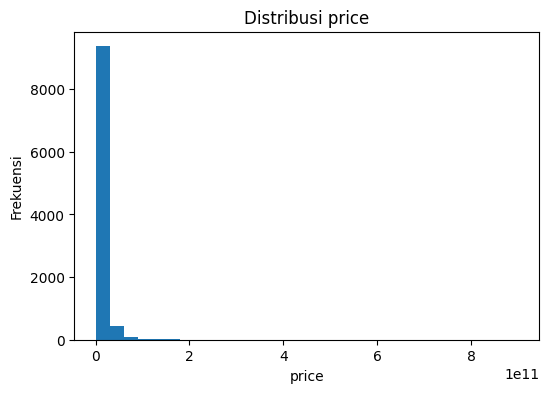

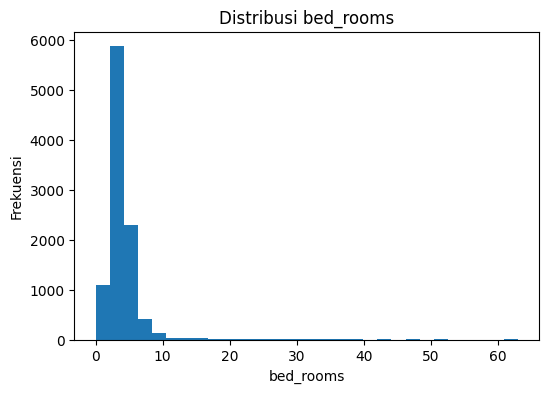

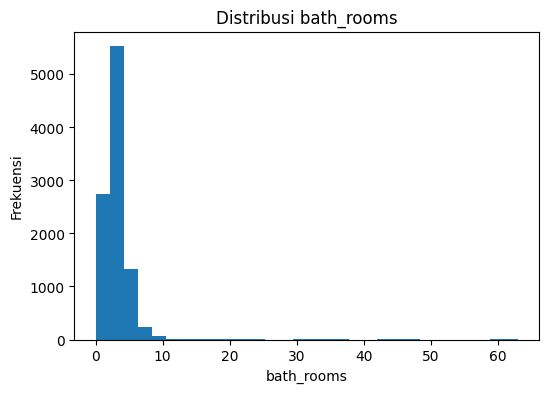

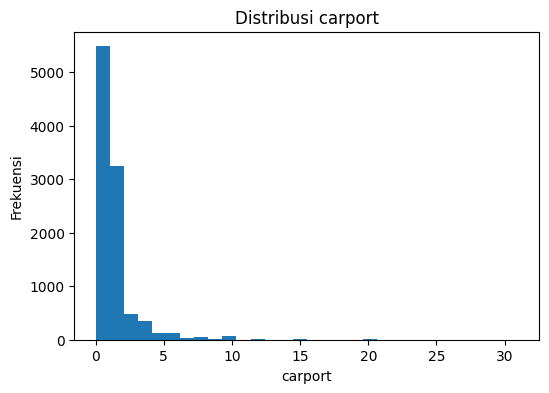

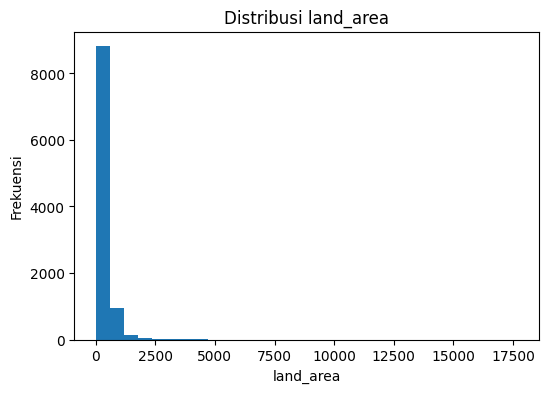

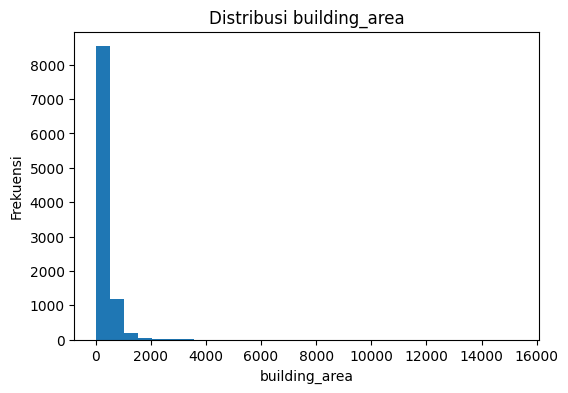

In [ ]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

### **2.3 Korelasi Antar Fitur**

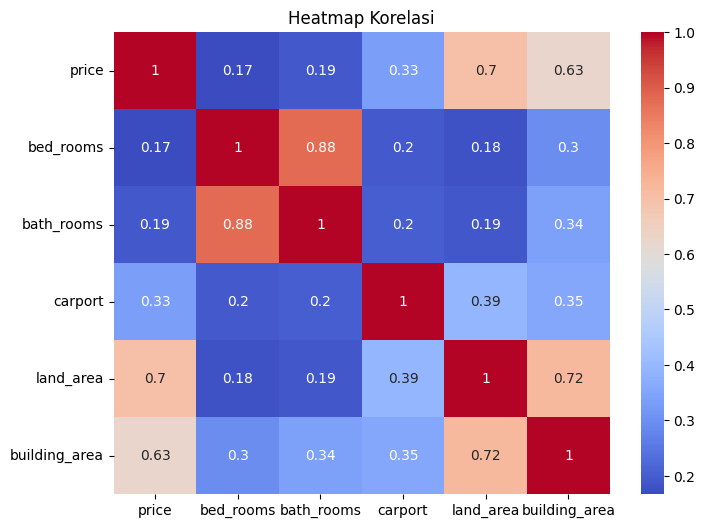

In [ ]:
corr = df[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Heatmap Korelasi')
plt.show()

# **3. PRA PENGOLAHAN DATA (Nuril_244107020004)**

### **3.1 Data Imputation / Mengisi Missing Value**

In [ ]:
# Modus
# df['land_area'] = df['land_area'].fillna(df['land_area'].mode()[0])
# df['building_area'] = df['building_area'].fillna(df['building_area'].mode()[0])

# Mean
# df['land_area'] = df['land_area'].fillna(df['land_area'].mean())
# df['building_area'] = df['building_area'].fillna(df['building_area'].mean())

# Median
df['land_area'] = df['land_area'].fillna(df['land_area'].median())
df['building_area'] = df['building_area'].fillna(df['building_area'].median())

### **3.2 Validasi Hasil Imputasi**

In [ ]:
df.info()

print()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB



,0
index,0
price,0
district,0
city,0
bed_rooms,0
bath_rooms,0
carport,0
land_area,0
building_area,0


### **3.3 Deteksi Outlier**

In [ ]:
# Menyimpan batas IQR awal
batas_iqr = {}

# Menentukan Kolom Numerik
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

# Menghitung Nilai Q1, Q3, IQR, Batas Outlier, dan Jumlah Outlier
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    # Simpan batas awal
    batas_iqr[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'bawah': batas_bawah,
        'atas': batas_atas
    }

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"\n===== {col} =====")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Batas Bawah :", batas_bawah)
    print("Batas Atas :", batas_atas)
    print("Jumlah Outlier :", jumlah_outlier)


===== price =====
Q1 : 2500000000.0
Q3 : 9800000000.0
IQR : 7300000000.0
Batas Bawah : -8450000000.0
Batas Atas : 20750000000.0
Jumlah Outlier : 1107

===== bed_rooms =====
Q1 : 3.0
Q3 : 5.0
IQR : 2.0
Batas Bawah : 0.0
Batas Atas : 8.0
Jumlah Outlier : 308

===== bath_rooms =====
Q1 : 2.0
Q3 : 4.0
IQR : 2.0
Batas Bawah : -1.0
Batas Atas : 7.0
Jumlah Outlier : 270

===== carport =====
Q1 : 1.0
Q3 : 2.0
IQR : 1.0
Batas Bawah : -0.5
Batas Atas : 3.5
Jumlah Outlier : 795

===== land_area =====
Q1 : 100.0
Q3 : 335.0
IQR : 235.0
Batas Bawah : -252.5
Batas Atas : 687.5
Jumlah Outlier : 881

===== building_area =====
Q1 : 139.0
Q3 : 400.0
IQR : 261.0
Batas Bawah : -252.5
Batas Atas : 791.5
Jumlah Outlier : 656


### **3.4 Penanganan Outlier**

In [ ]:
#Menyimpan jumlah data awal
jumlah_awal = len(df)

mask_outlier = pd.Series(False, index=df.index)

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    mask_outlier |= (
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    )

df = df[~mask_outlier]

print("Jumlah data sebelum :", jumlah_awal)
print("Jumlah data sesudah :", len(df))
print("Data yang terhapus :", jumlah_awal - len(df))

Jumlah data sebelum : 10000
Jumlah data sesudah : 8001
Data yang terhapus : 1999


### **3.5 Validasi Hasil Penanganan Outlier**

In [ ]:
# Mengecek Jumlah Data Setelah Penghapusan
for col in num_cols:

    batas_bawah = batas_iqr[col]['bawah']
    batas_atas = batas_iqr[col]['atas']

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"{col} : {jumlah_outlier}")


price : 0
bed_rooms : 0
bath_rooms : 0
carport : 0
land_area : 0
building_area : 0


### **3.6 Visualisasi Distribusi Data Setelah Penghapusan Outlier**

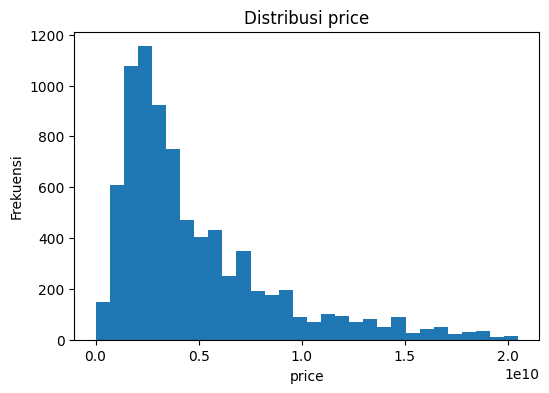

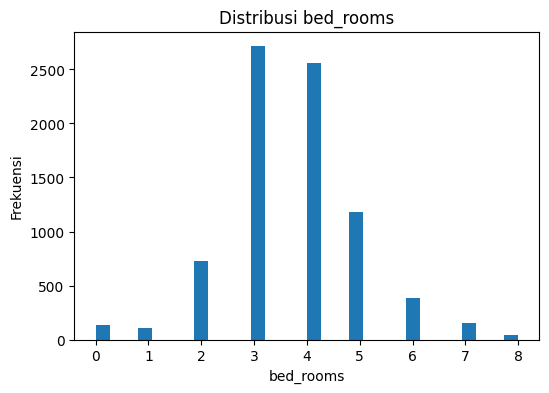

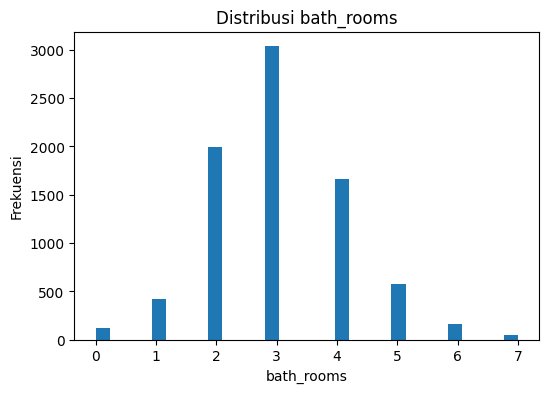

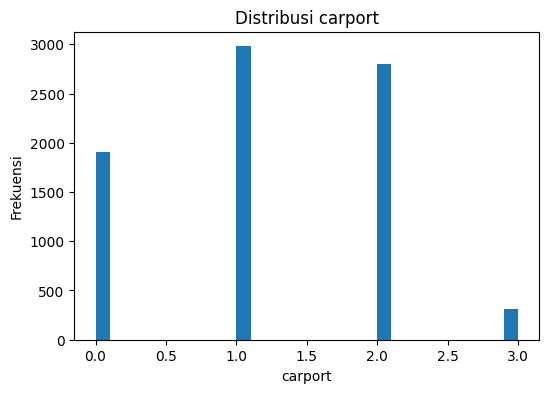

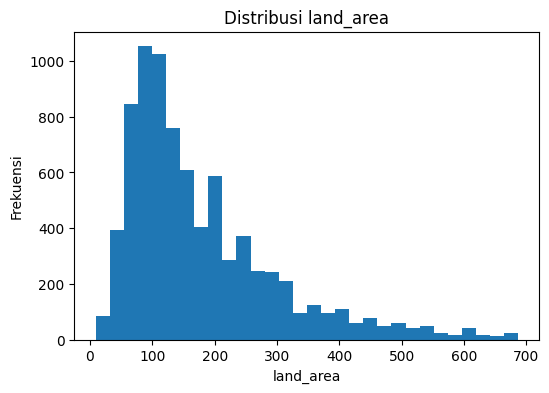

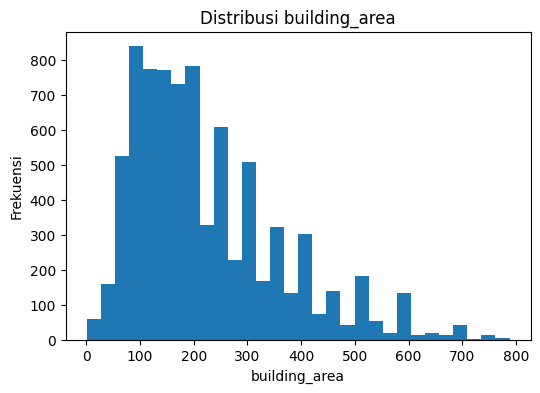

In [ ]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

### **3.8 Seleksi Fitur**

In [ ]:
df = df[
    [
        'price',
        'district',
        'city',
        'bed_rooms',
        'bath_rooms',
        'carport',
        'land_area',
        'building_area'
    ]
]

df.head()

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### **3.9 Encoding data kategorikal**

In [ ]:
le = LabelEncoder()

# District
df['district'] = le.fit_transform(df['district'])

# City
df['city'] = le.fit_transform(df['city'])

### **3.10 Verifikasi Hasil Encoding**

In [ ]:
df[['district', 'city']].head()

,district,city
0,37,0
1,70,0
2,70,0
3,70,0
4,224,0


### **3.11 Standarisasi**

In [ ]:
scaler = StandardScaler()

df = pd.DataFrame(scaler.fit_transform(df),columns=df.columns)

print("================ Hasil Setelah Standardisasi ================")
df.head()

================ Hasil Setelah Standardisasi ================


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,0.289543,-1.108788,-1.292805,-1.344695,0.832897,0.961320,0.589810,0.909888
1,-0.546548,-0.624150,-1.292805,0.240761,-0.888402,-1.413706,-0.642859,0.006773
2,-0.677188,-0.624150,-1.292805,-0.551967,-0.027752,-1.413706,-0.971571,-0.607344
3,-0.755571,-0.624150,-1.292805,-0.551967,-0.888402,-1.413706,-0.971571,-0.751843
4,-0.703315,1.637498,-1.292805,0.240761,-0.027752,-1.413706,-1.004442,-0.838542


# **4. MENENTUKAN JUMLAH CLUSTER (Nuril_244107020004)**

### **4.1 Menentukan Jumlah Cluster Dengan Metode Elbow**

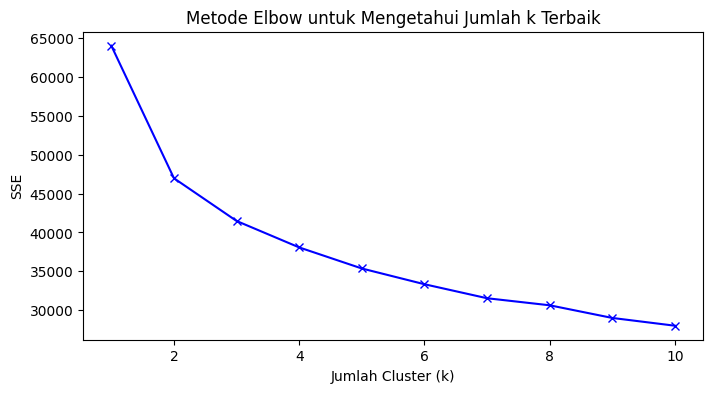

In [ ]:
# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1, 11)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(
     n_clusters=k,
     random_state=42
     )
 kmeanModel.fit(df)
 sse.append(kmeanModel.inertia_)

# Plotting SSE
plt.figure(figsize=(8,4))
plt.plot(K, sse, 'bx-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE')
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.show()

### **4.2 Menampilkan Nilai SSE Setiap k**

In [ ]:
for k, nilai_sse in zip(K, sse):
    print(f'k = {k}, SSE = {nilai_sse:.2f}')

k = 1, SSE = 64008.00
k = 2, SSE = 46968.84
k = 3, SSE = 41475.26
k = 4, SSE = 38074.59
k = 5, SSE = 35366.94
k = 6, SSE = 33342.12
k = 7, SSE = 31541.02
k = 8, SSE = 30635.02
k = 9, SSE = 29006.16
k = 10, SSE = 28008.18


### **4.3 Evaluasi Jumlah Cluster Menggunakan Silhouette Score**

In [ ]:
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42
        )

    labels = kmeans.fit_predict(df)

    score = silhouette_score(
        df,
        labels
    )

    print(f'k = {k}, silhouette = {score:.4f}')

k = 2, silhouette = 0.2724
k = 3, silhouette = 0.1586
k = 4, silhouette = 0.1470
k = 5, silhouette = 0.1588
k = 6, silhouette = 0.1470
k = 7, silhouette = 0.1550
k = 8, silhouette = 0.1454
k = 9, silhouette = 0.1495
k = 10, silhouette = 0.1467


Berdasarkan hasil perhitungan Silhouette Score untuk nilai k = 2 sampai k = 10, diperoleh nilai Silhouette Score tertinggi pada k = 2 yaitu sebesar 0,2724. Nilai ini lebih tinggi dibandingkan nilai k lainnya, sehingga menunjukkan bahwa pembagian data menjadi 2 cluster menghasilkan kualitas cluster yang paling baik. Oleh karena itu, jumlah cluster optimal yang digunakan pada penelitian ini adalah 2 cluster.

# **5. KMEANS - EUCLIDEAN DISTANCE (Nuril_244107020004)**

### **5.1 Visualisasi Data Awal**

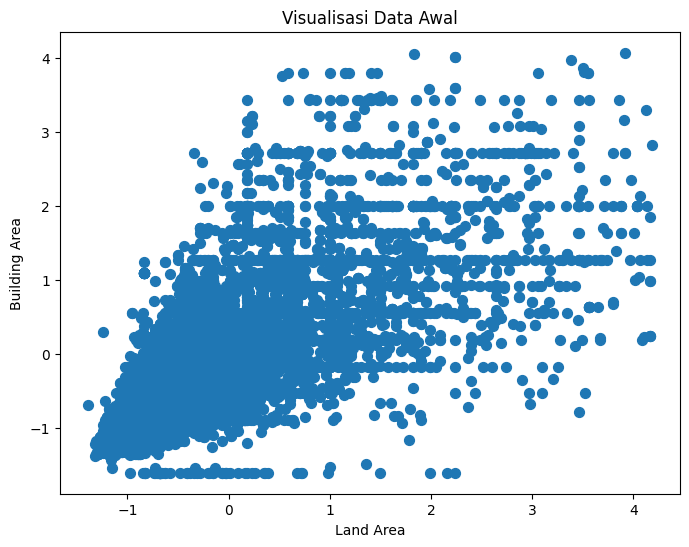

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

### **5.2 Model KMeans Euclidean Distance**

In [ ]:
start_time_kmeans_euclidean = time.time()

# Ubah dataframe menjadi array numpy
X = df.values

# Jumlah cluster
k = 2

# Random centroid awal
np.random.seed(42)
random_index = np.random.choice(len(X), k, replace=False)
centroids = X[random_index]

max_iter = 100

for iteration in range(max_iter):
    # List untuk menyimpan jarak
    distances = []

    for data in X:

        jarak_ke_centroid = []

        for centroid in centroids:

            jumlah = 0

            for i in range(len(data)):
                jumlah += (data[i] - centroid[i]) ** 2

            euclidean = jumlah ** 0.5

            jarak_ke_centroid.append(euclidean)

        distances.append(jarak_ke_centroid)

    distances = np.array(distances)

    # Tentukan cluster
    labels = np.argmin(distances, axis=1)

    # Hitung centroid baru
    new_centroids = []

    for cluster in range(k):

        anggota_cluster = X[labels == cluster]

        centroid_baru = anggota_cluster.mean(axis=0)

        new_centroids.append(centroid_baru)

    new_centroids = np.array(new_centroids)

    # Cek konvergen
    if np.allclose(centroids, new_centroids):
        print(f'Konvergen pada iterasi ke-{iteration+1}')
        break

    centroids = new_centroids

# Hasil akhir
y_kmeans_euclidean = labels

labels_asli_euclidean = labels.copy()

# Membalik label agar sama dengan hasil library
y_kmeans_euclidean = 1 - y_kmeans_euclidean

end_time_kmeans_euclidean = time.time()

Konvergen pada iterasi ke-19


Algoritma K-Means manual berhasil konvergen pada iterasi ke-19. Konvergen berarti posisi centroid sudah tidak berubah lagi secara signifikan, sehingga proses pengelompokan data dihentikan karena hasilnya sudah stabil.

### **5.3 Visualisasi Hasil Clustering KMeanc Euclidean Distance**

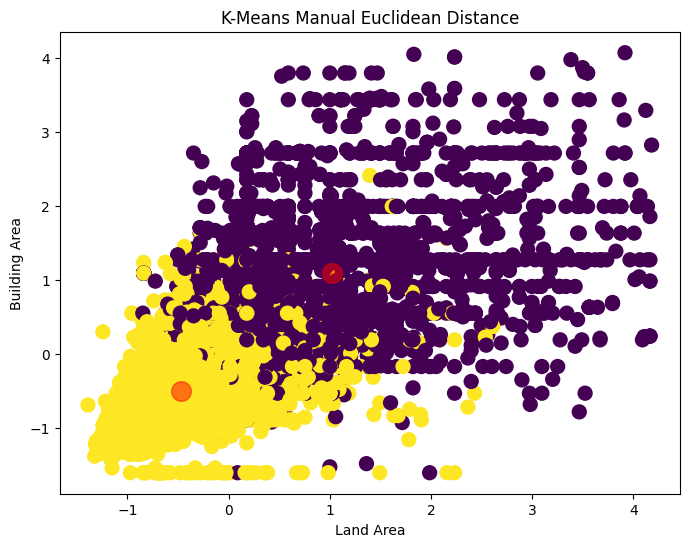

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=100,
    c=y_kmeans_euclidean
)

plt.scatter(
    centroids[:, 6],
    centroids[:, 7],
    c='red',
    s=200,
    alpha=0.5
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('K-Means Manual Euclidean Distance')

plt.show()

### **5.4 Evaluasi Kmeans Euclidean Distance**

In [ ]:
silhouette_kmeans_euclidean = silhouette_score(df,y_kmeans_euclidean)

dbi_kmeans_euclidean = davies_bouldin_score(df,y_kmeans_euclidean)

chi_kmeans_euclidean = calinski_harabasz_score(df,y_kmeans_euclidean)

execution_time_kmeans_euclidean = end_time_kmeans_euclidean - start_time_kmeans_euclidean

iterations_kmeans_euclidean = iteration + 1

sse_kmeans_euclidean = 0

for i in range(len(X)):
    cluster = labels_asli_euclidean[i]

    sse_kmeans_euclidean += np.sum(
        (X[i] - centroids[cluster]) ** 2)


### **5.5 Hasil Evaluasi KMeans Euclidean Distance**

In [ ]:
hasil_euclidean = pd.DataFrame({
    'Metode': ['K-Means Eucledian Distance'],
    'Jumlah Cluster': [k],
    'Silhouette': [silhouette_kmeans_euclidean],
    'DBI': [dbi_kmeans_euclidean],
    'CHI': [chi_kmeans_euclidean],
    'Execution Time': [execution_time_kmeans_euclidean],
    'Iterations': [iterations_kmeans_euclidean],
    'SSE': [sse_kmeans_euclidean]
})
print("=" * 80)
print("TABEL EVALUASI K-MEANS EUCLIDEAN DISTANCE")
print("=" * 80)


print(hasil_euclidean.to_string(index=False))

TABEL EVALUASI K-MEANS EUCLIDEAN DISTANCE
                    Metode  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time  Iterations          SSE
K-Means Eucledian Distance               2    0.272507 1.545344 2901.855067        2.348547          19 46968.791791


# **6. KMEANS - MANHATTAN DISTANCE (Hanif_244107020232)**

### **6.1 Visualisasi Data Awal**

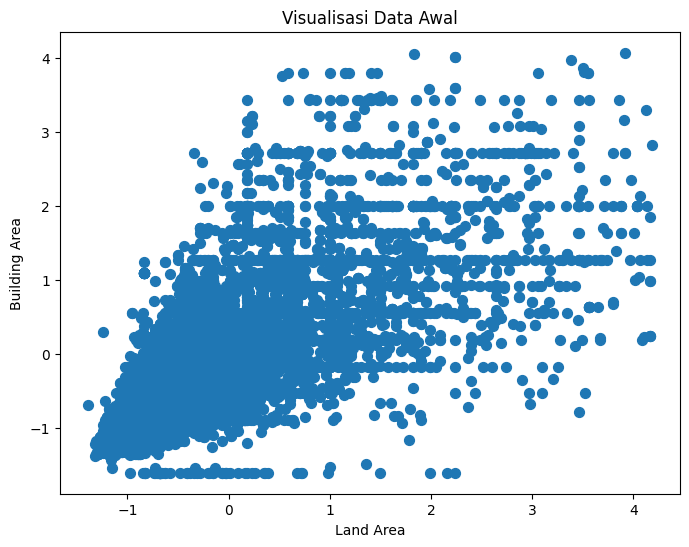

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

### **6.2 Model KMeans Manhattan**

In [ ]:
start_time_kmeans_manhattan = time.time()

# Ubah dataframe menjadi array numpy
X = df.values

# Jumlah cluster
k = 2

# Random centroid awal
np.random.seed(42)
random_index = np.random.choice(len(X), k, replace=False)
centroids = X[random_index]

max_iter = 100

for iteration in range(max_iter):

    # List untuk menyimpan jarak
    distances = []

    for data in X:

        jarak_ke_centroid = []

        for centroid in centroids:

            jumlah = 0

            for i in range(len(data)):
                jumlah += abs(data[i] - centroid[i])

            manhattan = jumlah

            jarak_ke_centroid.append(manhattan)

        distances.append(jarak_ke_centroid)

    distances = np.array(distances)

    # Tentukan cluster
    labels = np.argmin(distances, axis=1)

    # Hitung centroid baru
    new_centroids = []

    for cluster in range(k):

        anggota_cluster = X[labels == cluster]

        # Median digunakan pada Manhattan
        centroid_baru = np.median(anggota_cluster, axis=0)

        new_centroids.append(centroid_baru)

    new_centroids = np.array(new_centroids)

    # Cek konvergen
    if np.allclose(centroids, new_centroids):
        print(f'Konvergen pada iterasi ke-{iteration+1}')
        break

    centroids = new_centroids

# Hasil akhir
y_kmeans_manhattan = labels

labels_asli_manhattan = labels.copy()

# Membalik label agar sama dengan hasil library
y_kmeans_manhattan = 1 - y_kmeans_manhattan

end_time_kmeans_manhattan = time.time()

Konvergen pada iterasi ke-9


### **6.3 Visualisasi Hasil Clustering KMeans Manhattan**

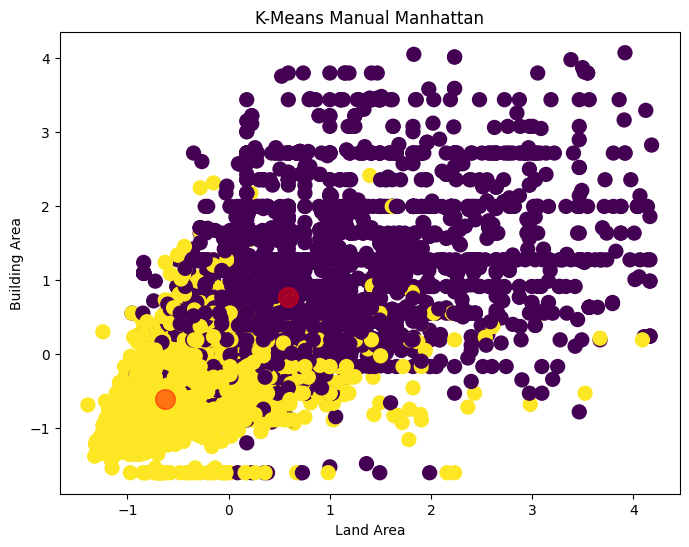

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=100,
    c=y_kmeans_manhattan
)

plt.scatter(
    centroids[:, 6],
    centroids[:, 7],
    c='red',
    s=200,
    alpha=0.5
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('K-Means Manual Manhattan')

plt.show()

### **6.4 Evaluasi Kmeans Manhattan**

In [ ]:
silhouette_kmeans_manhattan = silhouette_score(df,y_kmeans_manhattan,metric='manhattan')

dbi_kmeans_manhattan = davies_bouldin_score(df,y_kmeans_manhattan)

chi_kmeans_manhattan = calinski_harabasz_score(df,y_kmeans_manhattan)

execution_time_kmeans_manhattan = end_time_kmeans_manhattan - start_time_kmeans_manhattan

iterations_kmeans_manhattan = iteration + 1

sse_kmeans_manhattan = 0

for i in range(len(X)):
    cluster = labels_asli_manhattan[i]

    sse_kmeans_manhattan += np.sum(
        (X[i] - centroids[cluster]) ** 2)


### **6.5 Hasil Evaluasi KMeans Manhattan**

In [ ]:
hasil_manhattan = pd.DataFrame({
    'Metode': ['K-Means Manhattan'],
    'Jumlah Cluster': [k],
    'Silhouette': [silhouette_kmeans_manhattan],
    'DBI': [dbi_kmeans_manhattan],
    'CHI': [chi_kmeans_manhattan],
    'Execution Time': [execution_time_kmeans_manhattan],
    'Iterations': [iterations_kmeans_manhattan],
    'SSE': [sse_kmeans_manhattan]
})
print("=" * 80)
print("TABEL EVALUASI K-MEANS MANHATTAN")
print("=" * 80)


print(hasil_manhattan.to_string(index=False))

TABEL EVALUASI K-MEANS MANHATTAN
           Metode  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time  Iterations          SSE
K-Means Manhattan               2    0.291949 1.647277 2678.175533        1.861229           9 51096.552646


# **7. KMEANS - COSINE DISTANCE (Hanif_244107020232)**

### **7.1 Visualisasi Data Awal**

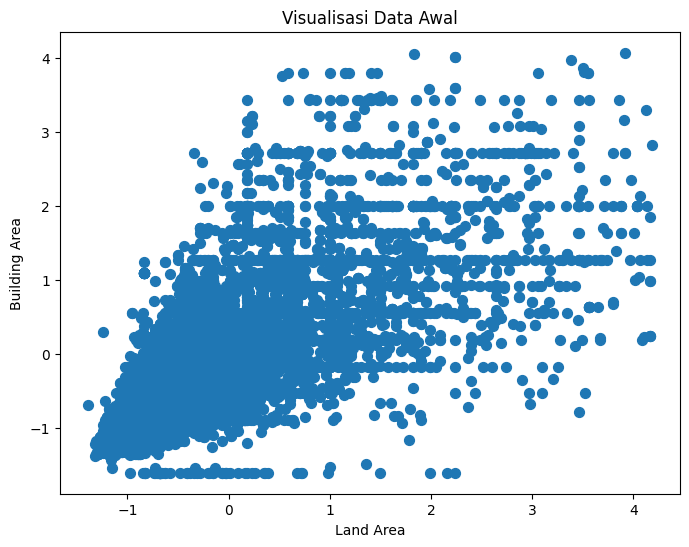

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

### **7.2 Model KMeans Cosine**

In [ ]:
start_time_kmeans_cosine = time.time()

# Ubah dataframe menjadi array numpy
X = df.values

# Jumlah cluster
k = 2

# Random centroid awal
np.random.seed(42)
random_index = np.random.choice(len(X), k, replace=False)
centroids = X[random_index]

max_iter = 100

for iteration in range(max_iter):
    # List untuk menyimpan jarak cosine
    distances = []

    for data in X:

        cosine_distance_ke_centroid = []

        for centroid in centroids:

            # Hitung dot product
            dot_product = 0
            norm_data = 0
            norm_centroid = 0

            for i in range(len(data)):
                dot_product += data[i] * centroid[i]
                norm_data += data[i] ** 2
                norm_centroid += centroid[i] ** 2

            norm_data = norm_data ** 0.5
            norm_centroid = norm_centroid ** 0.5

            # Cosine Similarity
            cosine_similarity = dot_product / (norm_data * norm_centroid)

            # Cosine Distance
            cosine_distance = 1 - cosine_similarity

            cosine_distance_ke_centroid.append(cosine_distance)

        distances.append(cosine_distance_ke_centroid)

    distances = np.array(distances)

    # Tentukan cluster berdasarkan cosine distance terkecil
    labels = np.argmin(distances, axis=1)

    # Hitung centroid baru
    new_centroids = []

    for cluster in range(k):

        anggota_cluster = X[labels == cluster]

        # Gunakan mean seperti K-Means
        centroid_baru = anggota_cluster.mean(axis=0)

        new_centroids.append(centroid_baru)

    new_centroids = np.array(new_centroids)

    # Cek konvergen
    if np.allclose(centroids, new_centroids, atol=1e-4):
        print(f'Konvergen pada iterasi ke-{iteration+1}')
        break

    centroids = new_centroids

# Hasil akhir
y_kmeans_cosine = labels

labels_asli_cosine = labels.copy()

# Membalik label agar sama dengan hasil library
y_kmeans_cosine = 1 - y_kmeans_cosine

end_time_kmeans_cosine = time.time()

Konvergen pada iterasi ke-9


### **7.3 Visualisasi Hasil Clustering KMeans Cosine**

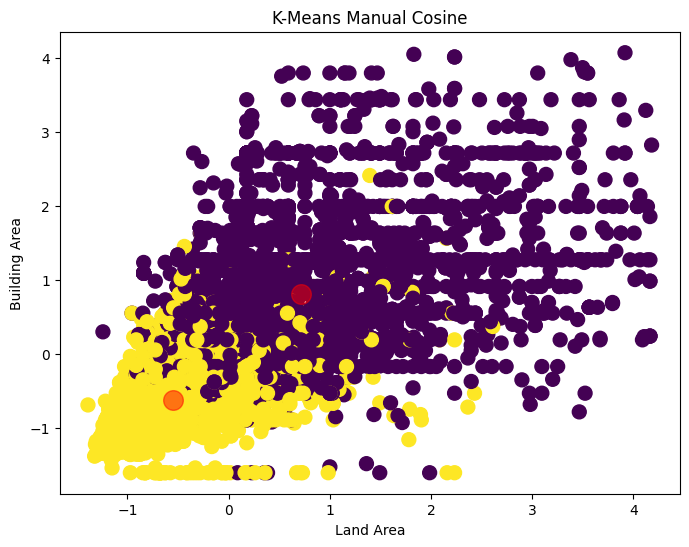

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=100,
    c=y_kmeans_cosine
)

plt.scatter(
    centroids[:, 6],
    centroids[:, 7],
    c='red',
    s=200,
    alpha=0.5
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('K-Means Manual Cosine')

plt.show()

### **7.4 Evaluasi Kmeans Cosine**

In [ ]:
silhouette_kmeans_cosine = silhouette_score(df,y_kmeans_cosine,metric='cosine')

dbi_kmeans_cosine = davies_bouldin_score(df,y_kmeans_cosine)

chi_kmeans_cosine = calinski_harabasz_score(df,y_kmeans_cosine)

execution_time_kmeans_cosine = end_time_kmeans_cosine - start_time_kmeans_cosine

iterations_kmeans_cosine = iteration + 1

sse_kmeans_cosine = 0

for i in range(len(X)):
    cluster = labels_asli_cosine[i]

    sse_kmeans_cosine += np.sum(
        (X[i] - centroids[cluster]) ** 2)


### **7.5 Hasil Evaluasi KMeans Cosine**

In [ ]:
hasil_cosine = pd.DataFrame({
    'Metode': ['K-Means Cosine'],
    'Jumlah Cluster': [k],
    'Silhouette': [silhouette_kmeans_cosine],
    'DBI': [dbi_kmeans_cosine],
    'CHI': [chi_kmeans_cosine],
    'Execution Time': [execution_time_kmeans_cosine],
    'Iterations': [iterations_kmeans_cosine],
    'SSE': [sse_kmeans_cosine]
})
print("=" * 80)
print("TABEL EVALUASI K-MEANS COSINE")
print("=" * 80)


print(hasil_cosine.to_string(index=False))

TABEL EVALUASI K-MEANS COSINE
        Metode  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time  Iterations          SSE
K-Means Cosine               2    0.374234 1.632044 2783.303407        1.997009           9 47485.214675


# **8. DBSCAN - EUCLIDEAN DISTANCE (NaufalAbid_244107020212)**

### **8.1 Menentukan min_samples Awal**

In [ ]:
min_samples_awal_euclidean = 2 * df.shape[1]
print("Min Samples :", min_samples_awal_euclidean)

Min Samples : 16


### **8.2 K-Distance Graph**

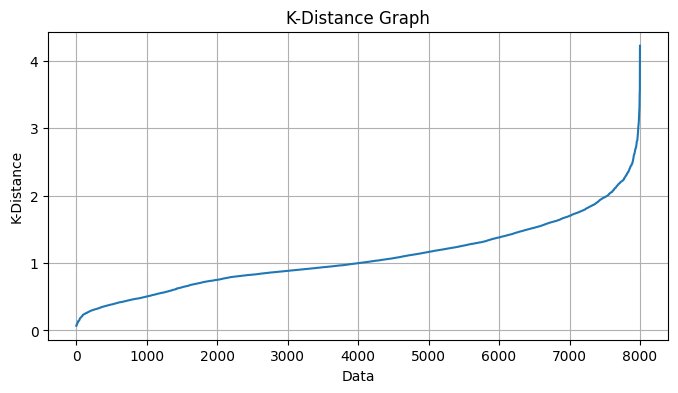

In [ ]:
neighbors = NearestNeighbors(
    n_neighbors=min_samples_awal_euclidean,
    metric='euclidean'
)

neighbors_fit = neighbors.fit(df)

distances, indices = neighbors_fit.kneighbors(df)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(distances)

plt.xlabel('Data')
plt.ylabel('K-Distance')
plt.title('K-Distance Graph')
plt.grid(True)
plt.show()

### **8.3 Mencari Eps Terbaik**

In [ ]:
list_min_samples_euclidean = [
    min_samples_awal_euclidean // 2,
    min_samples_awal_euclidean,
    min_samples_awal_euclidean * 2
]
list_eps_euclidean = np.round(np.arange(0.1, 4.21, 0.1),2)

hasil_eps = []

for min_samples in list_min_samples_euclidean:

    for eps in list_eps_euclidean:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean'
        )

        labels = dbscan.fit_predict(X)

        # Menghilangkan noise untuk evaluasi
        mask = labels != -1

        # Jumlah cluster
        jumlah_cluster = len(set(labels)) - (
            1 if -1 in labels else 0
        )

        # Jumlah noise
        jumlah_noise = np.sum(labels == -1)

        # Silhouette Score
        if jumlah_cluster > 1:

            silhouette = silhouette_score(
                X[mask],
                labels[mask],
                metric='euclidean'
            )
        else:
            silhouette = np.nan

        hasil_eps.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Cluster': jumlah_cluster,
            'Jumlah Noise': jumlah_noise,
            'Noise_ratio (%)': round(jumlah_noise / len(df) * 100, 2),
            'Silhouette': silhouette
        })

df_grid_euclidean = pd.DataFrame(hasil_eps)

df_grid_euclidean

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise_ratio (%),Silhouette
0,0.1,8,9,7891,98.63,0.941926
1,0.2,8,38,7481,93.50,0.711227
2,0.3,8,67,6788,84.84,0.566423
3,0.4,8,78,6120,76.49,0.466621
4,0.5,8,101,5578,69.72,0.384148
...,...,...,...,...,...,...
121,3.8,32,1,0,0.00,NaN
122,3.9,32,1,0,0.00,NaN
123,4.0,32,1,0,0.00,NaN
124,4.1,32,1,0,0.00,NaN


### **8.4 Memilih Parameter Terbaik**

Kriteria: jumlah cluster ≥ 2, proporsi noise ≤ 20%, dan Silhouette Score tertinggi. Jika tidak ada yang memenuhi batas noise, batas tersebut diabaikan.

In [ ]:
# Mengambil hasil dengan minimal 2 cluster
valid = df_grid_euclidean[df_grid_euclidean['Jumlah Cluster'] >= 2]

# Memilih hasil dengan noise maksimal 20%
valid_noise = valid[valid['Noise_ratio (%)'] <= 20]

# Jika tidak ada, batas noise diabaikan
if len(valid_noise) > 0:
    kandidat = valid_noise
else:
    kandidat = valid

# Memilih Silhouette Score tertinggi
terbaik = kandidat.loc[kandidat['Silhouette'].idxmax()]

# Menyimpan parameter terbaik
eps_euclidean = float(terbaik['eps'])
min_samples_euclidean = int(terbaik['min_samples'])

# Menampilkan parameter terbaik
print("Parameter terbaik:")
print(terbaik)
print()
print("eps         :", eps_euclidean)
print("min_samples :", min_samples_euclidean)

Parameter terbaik:
eps                  1.500000
min_samples          8.000000
Jumlah Cluster       3.000000
Jumlah Noise       488.000000
Noise_ratio (%)      6.100000
Silhouette           0.323696
Name: 14, dtype: float64

eps         : 1.5
min_samples : 8


### **8.5 Visualisasi Data Awal**

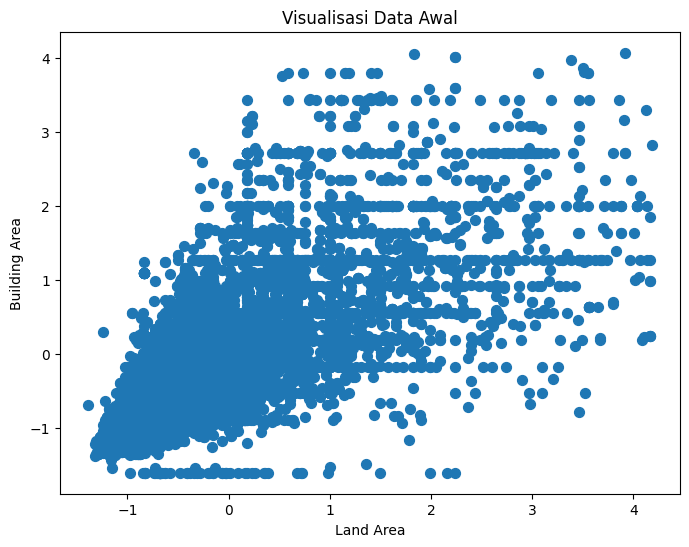

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

### **8.6 Model DBSCAN Euclidean Distance**

In [ ]:
start_time_dbscan_euclidean = time.time()

# Ubah dataframe menjadi array numpy
X = df.values

# Jumlah data
n = len(X)

# Cari tetangga setiap data
neighbors = []

for data in X:

    jarak = np.sqrt(np.sum((X - data) ** 2, axis=1))

    tetangga = np.where(jarak <= eps_euclidean)[0]

    neighbors.append(tetangga)

# Tentukan Core Point
core_points = []

for tetangga in neighbors:

    if len(tetangga) >= min_samples_euclidean:
        core_points.append(True)
    else:
        core_points.append(False)

core_points = np.array(core_points)

# Tentukan cluster
labels = np.full(n, -1)

cluster = 0

for i in range(n):

    if not core_points[i] or labels[i] != -1:
        continue

    labels[i] = cluster

    queue = [i]

    while queue:

        p = queue.pop(0)

        if not core_points[p]:
            continue

        for q in neighbors[p]:

            if labels[q] == -1:
                labels[q] = cluster
                queue.append(q)

    cluster += 1

# Hasil akhir
y_dbscan_euclidean = labels

end_time_dbscan_euclidean = time.time()

### **8.7 Visualisasi Hasil Clustering DBSCAN Euclidean Distance**

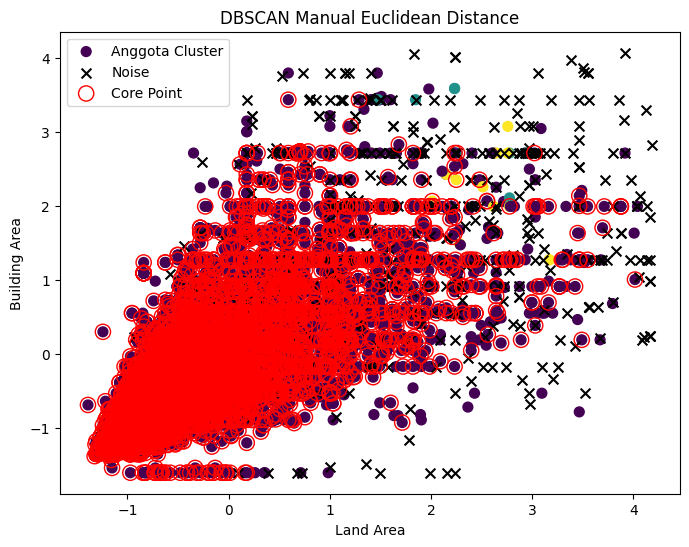

In [ ]:
plt.figure(figsize=(8,6))

# Noise
noise = y_dbscan_euclidean == -1

# Anggota cluster
plt.scatter(
    df['land_area'][~noise],
    df['building_area'][~noise],
    c=y_dbscan_euclidean[~noise],
    s=50,
    cmap='viridis',
    label='Anggota Cluster'
)

# Noise
plt.scatter(
    df['land_area'][noise],
    df['building_area'][noise],
    c='black',
    marker='x',
    s=50,
    label='Noise'
)

# Core Point
plt.scatter(
    df['land_area'][core_points],
    df['building_area'][core_points],
    facecolors='none',
    edgecolors='red',
    s=120,
    label='Core Point'
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('DBSCAN Manual Euclidean Distance')

plt.legend()
plt.show()

### **8.8 Evaluasi DBSCANN Euclidean Distance**

In [ ]:
# Execution time
execution_time_dbscan_euclidean = (end_time_dbscan_euclidean - start_time_dbscan_euclidean)

# Jumlah cluster
n_cluster_dbscan_euclidean = len(set(y_dbscan_euclidean)) - (1 if -1 in y_dbscan_euclidean else 0)

# Jumlah noise
n_noise_dbscan_euclidean = np.sum(y_dbscan_euclidean == -1)

# Data yang bukan noise
mask_euclidean = y_dbscan_euclidean != -1

X_cluster_euclidean = X[mask_euclidean]
labels_cluster_euclidean = y_dbscan_euclidean[mask_euclidean]

# Evaluasi
if len(set(labels_cluster_euclidean)) > 1:

    silhouette_dbscan_euclidean = silhouette_score(
        X_cluster_euclidean,
        labels_cluster_euclidean,
        metric='euclidean'
    )

    dbi_dbscan_euclidean = davies_bouldin_score(
        X_cluster_euclidean,
        labels_cluster_euclidean
    )

    ch_dbscan_euclidean = calinski_harabasz_score(
        X_cluster_euclidean,
        labels_cluster_euclidean
    )

else:
    silhouette_dbscan_euclidean = np.nan
    dbi_dbscan_euclidean = np.nan
    ch_dbscan_euclidean = np.nan

### **8.9 Hasil Evaluasi DBSCAN Euclidean Distance**

In [ ]:
hasil_dbscan_euclidean = pd.DataFrame({

    'Metode': ['DBSCAN Euclidean'],

    'Jumlah Cluster': [n_cluster_dbscan_euclidean],

    'Jumlah Noise': [n_noise_dbscan_euclidean],

    'Silhouette': [silhouette_dbscan_euclidean],

    'DBI': [dbi_dbscan_euclidean],

    'CHI': [ch_dbscan_euclidean],

    'Execution Time': [execution_time_dbscan_euclidean]

})

print("=" * 80)

print("TABEL EVALUASI DBSCAN EUCLIDEAN DISTANCE")

print("=" * 80)

print(hasil_dbscan_euclidean.to_string(index=False))

TABEL EVALUASI DBSCAN EUCLIDEAN DISTANCE
          Metode  Jumlah Cluster  Jumlah Noise  Silhouette      DBI       CHI  Execution Time
DBSCAN Euclidean               3           488    0.323696 0.712345 43.650386        3.122118


# **9. DBSCAN - MANHATTAN DISTANCE (Jasmine_244107020119)**

### **9.1 Menentukan min_samples Awal**

In [ ]:
min_samples_awal_manhattan = 2 * df.shape[1]
print("Min Samples :", min_samples_awal_manhattan)

Min Samples : 16


### **9.2 K-Distance Graph**

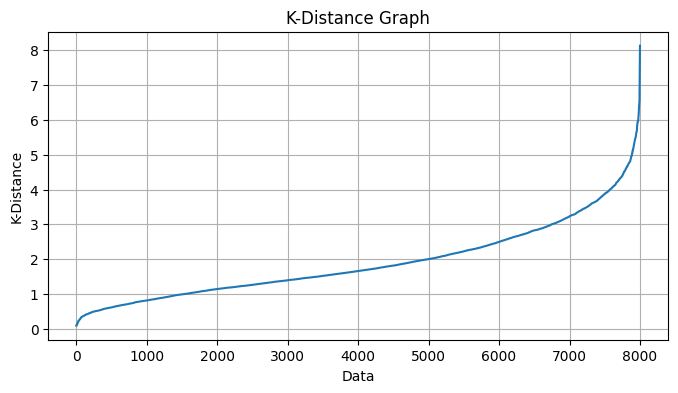

In [ ]:
neighbors = NearestNeighbors(
    n_neighbors=min_samples_awal_manhattan,
    metric='manhattan'
)

neighbors_fit = neighbors.fit(df)

distances, indices = neighbors_fit.kneighbors(df)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(distances)

plt.xlabel('Data')
plt.ylabel('K-Distance')
plt.title('K-Distance Graph')
plt.grid(True)
plt.show()

### **9.3 Mencari Eps Terbaik**

In [ ]:
list_min_samples_manhattan = [
    min_samples_awal_manhattan // 2,
    min_samples_awal_manhattan,
    min_samples_awal_manhattan * 2
]
list_eps_manhattan = np.round(np.arange(0.1, 8.21, 0.1),2)

hasil_eps = []

for min_samples in list_min_samples_manhattan:

    for eps in list_eps_manhattan:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='manhattan'
        )

        labels = dbscan.fit_predict(X)

        # Menghilangkan noise untuk evaluasi
        mask = labels != -1

        # Jumlah cluster
        jumlah_cluster = len(set(labels)) - (
            1 if -1 in labels else 0
        )

        # Jumlah noise
        jumlah_noise = np.sum(labels == -1)

        # Silhouette Score
        if jumlah_cluster > 1:

            silhouette = silhouette_score(
                X[mask],
                labels[mask],
                metric='manhattan'
            )
        else:
            silhouette = np.nan

        hasil_eps.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Cluster': jumlah_cluster,
            'Jumlah Noise': jumlah_noise,
            'Noise_ratio (%)': round(jumlah_noise / len(df) * 100, 2),
            'Silhouette': silhouette
        })

df_grid_manhattan = pd.DataFrame(hasil_eps)

df_grid_manhattan

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise_ratio (%),Silhouette
0,0.1,8,6,7937,99.20,0.972082
1,0.2,8,16,7802,97.51,0.839108
2,0.3,8,39,7454,93.16,0.701236
3,0.4,8,57,7058,88.21,0.613238
4,0.5,8,70,6608,82.59,0.553962
...,...,...,...,...,...,...
241,7.8,32,1,0,0.00,NaN
242,7.9,32,1,0,0.00,NaN
243,8.0,32,1,0,0.00,NaN
244,8.1,32,1,0,0.00,NaN


### **9.4 Memilih Parameter Terbaik**

Kriteria: jumlah cluster ≥ 2, proporsi noise ≤ 20%, dan Silhouette Score tertinggi. Jika tidak ada yang memenuhi batas noise, batas tersebut diabaikan.

In [ ]:
# Mengambil hasil dengan minimal 2 cluster
valid = df_grid_manhattan[df_grid_manhattan['Jumlah Cluster'] >= 2]

# Memilih hasil dengan noise maksimal 20%
valid_noise = valid[valid['Noise_ratio (%)'] <= 20]

# Jika tidak ada, batas noise diabaikan
if len(valid_noise) > 0:
    kandidat = valid_noise
else:
    kandidat = valid

# Memilih Silhouette Score tertinggi
terbaik = kandidat.loc[kandidat['Silhouette'].idxmax()]

# Menyimpan parameter terbaik
eps_manhattan = float(terbaik['eps'])
min_samples_manhattan = int(terbaik['min_samples'])

# Menampilkan parameter terbaik
print("Parameter terbaik:")
print(terbaik)
print()
print("eps         :", eps_manhattan)
print("min_samples :", min_samples_manhattan)

Parameter terbaik:
eps                  3.500000
min_samples          8.000000
Jumlah Cluster       2.000000
Jumlah Noise       123.000000
Noise_ratio (%)      1.540000
Silhouette           0.433572
Name: 34, dtype: float64

eps         : 3.5
min_samples : 8


### **9.5 Visualisasi Data Awal**

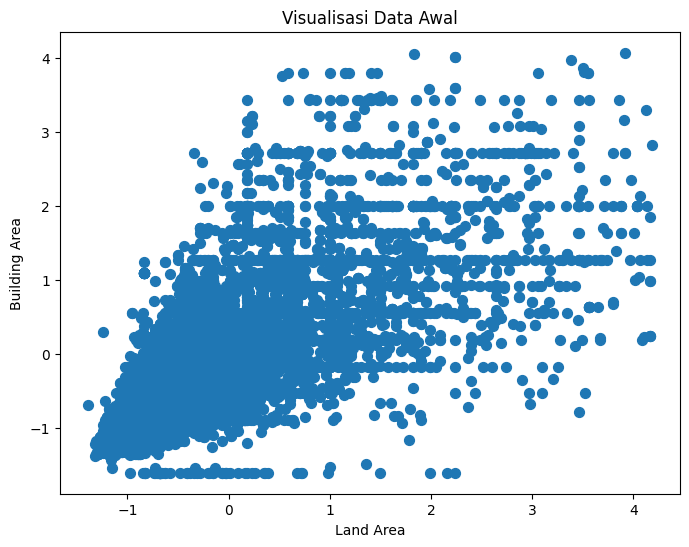

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

### **9.6 Model DBSCAN Manhattan Distance**

In [ ]:
start_time_dbscan_manhattan = time.time()

X = df.values
n = len(X)

# Mencari tetangga menggunakan Manhattan Distance
neighbors = []

for data in X:

    jarak = np.sum(np.abs(X - data), axis=1)

    tetangga = np.where(jarak <= eps_manhattan)[0]

    neighbors.append(tetangga)


# Menentukan Core Point
core_points = []

for tetangga in neighbors:

    if len(tetangga) >= min_samples_manhattan:
        core_points.append(True)
    else:
        core_points.append(False)

core_points = np.array(core_points)


# Inisialisasi label
labels = np.full(n, -1)

cluster = 0

# Membentuk cluster
for i in range(n):

    if not core_points[i] or labels[i] != -1:
        continue

    labels[i] = cluster

    queue = [i]

    while queue:

        p = queue.pop(0)

        if not core_points[p]:
            continue

        for q in neighbors[p]:

            if labels[q] == -1:

                labels[q] = cluster
                queue.append(q)

    cluster += 1


y_dbscan_manhattan = labels

end_time_dbscan_manhattan = time.time()

### **9.7 Visualisasi Hasil Clustering DBSCAN Manhattan Distance**

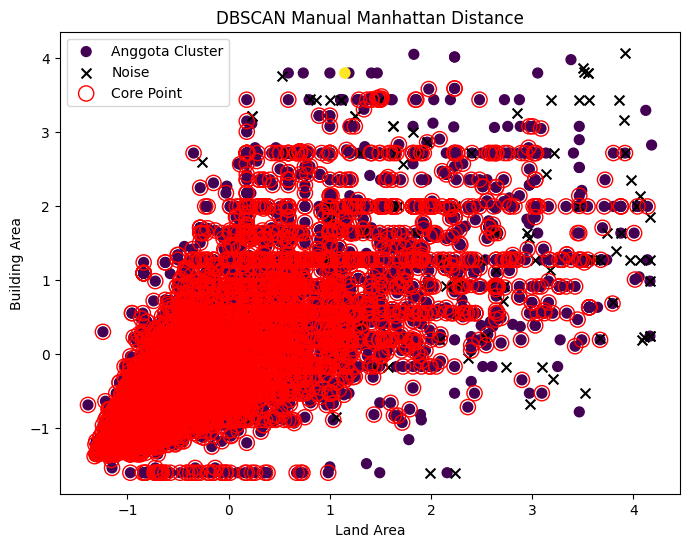

In [ ]:
plt.figure(figsize=(8,6))

# Noise
noise = y_dbscan_manhattan == -1

# Anggota cluster
plt.scatter(
    df['land_area'][~noise],
    df['building_area'][~noise],
    c=y_dbscan_manhattan[~noise],
    s=50,
    cmap='viridis',
    label='Anggota Cluster'
)

# Noise
plt.scatter(
    df['land_area'][noise],
    df['building_area'][noise],
    c='black',
    marker='x',
    s=50,
    label='Noise'
)

# Core Point
plt.scatter(
    df['land_area'][core_points],
    df['building_area'][core_points],
    facecolors='none',
    edgecolors='red',
    s=120,
    label='Core Point'
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('DBSCAN Manual Manhattan Distance')

plt.legend()
plt.show()

### **9.8 Evaluasi DBSCANN Manhattan Distance**

In [ ]:
# Execution time
execution_time_dbscan_manhattan = (
    end_time_dbscan_manhattan - start_time_dbscan_manhattan
)

# Jumlah cluster
n_cluster_dbscan_manhattan = len(set(y_dbscan_manhattan)) - (
    1 if -1 in y_dbscan_manhattan else 0
)

# Jumlah noise
n_noise_dbscan_manhattan = np.sum(
    y_dbscan_manhattan == -1
)


# Data yang bukan noise
mask_manhattan = y_dbscan_manhattan != -1

X_cluster_manhattan = X[mask_manhattan]
labels_cluster_manhattan = y_dbscan_manhattan[mask_manhattan]


# Evaluasi
if len(set(labels_cluster_manhattan)) > 1:

    silhouette_dbscan_manhattan = silhouette_score(
        X_cluster_manhattan,
        labels_cluster_manhattan,
        metric='manhattan'
    )

    dbi_dbscan_manhattan = davies_bouldin_score(
        X_cluster_manhattan,
        labels_cluster_manhattan
    )

    ch_dbscan_manhattan = calinski_harabasz_score(
        X_cluster_manhattan,
        labels_cluster_manhattan
    )

else:

    silhouette_dbscan_manhattan = np.nan
    dbi_dbscan_manhattan = np.nan
    ch_dbscan_manhattan = np.nan

### **9.9 Hasil Evaluasi DBSCAN Manhattan Distance**

In [ ]:
hasil_dbscan_manhattan = pd.DataFrame({

    'Metode': ['DBSCAN Manhattan'],

    'Jumlah Cluster': [n_cluster_dbscan_manhattan],

    'Jumlah Noise': [n_noise_dbscan_manhattan],

    'Silhouette': [silhouette_dbscan_manhattan],

    'DBI': [dbi_dbscan_manhattan],

    'CHI': [ch_dbscan_manhattan],

    'Execution Time': [execution_time_dbscan_manhattan]

})

print("=" * 80)

print("TABEL EVALUASI DBSCAN MANHATTAN DISTANCE")

print("=" * 80)

print(hasil_dbscan_manhattan.to_string(index=False))

TABEL EVALUASI DBSCAN MANHATTAN DISTANCE
          Metode  Jumlah Cluster  Jumlah Noise  Silhouette      DBI       CHI  Execution Time
DBSCAN Manhattan               2           123    0.433572 0.604611 18.733536        2.558322


# **10. DBSCAN - COSINE (Nurfinka Lailasari_244107020211)**

### **10.1 Menentukan min_samples Awal**

In [ ]:
min_samples_awal_cosine = 2 * df.shape[1]
print("Min Samples :", min_samples_awal_cosine)

Min Samples : 16


### **10.2 K-Distance Graph**

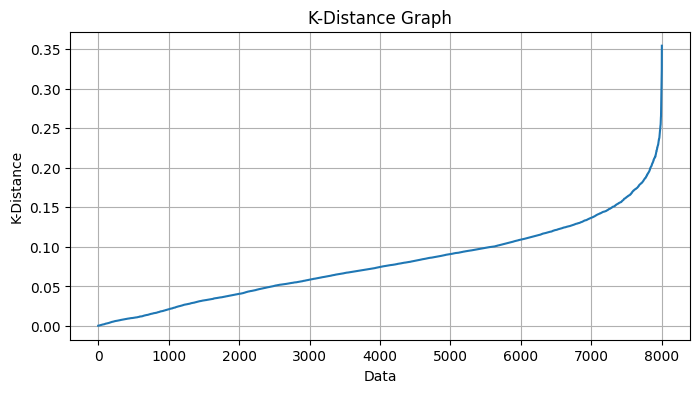

In [ ]:
neighbors = NearestNeighbors(
    n_neighbors=min_samples_awal_cosine,
    metric='cosine'
)

neighbors_fit = neighbors.fit(df)

distances, indices = neighbors_fit.kneighbors(df)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(distances)

plt.xlabel('Data')
plt.ylabel('K-Distance')
plt.title('K-Distance Graph')
plt.grid(True)
plt.show()

### **10.3 Mencari Eps Terbaik**

In [ ]:
list_min_samples_cosine = [
    min_samples_awal_cosine // 2,
    min_samples_awal_cosine,
    min_samples_awal_cosine * 2
]
list_eps_cosine = np.round(np.arange(0.01, 0.36, 0.01),2)

hasil_eps = []

for min_samples in list_min_samples_cosine:

    for eps in list_eps_cosine:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='cosine'
        )

        labels = dbscan.fit_predict(X)

        # Menghilangkan noise untuk evaluasi
        mask = labels != -1

        # Jumlah cluster
        jumlah_cluster = len(set(labels)) - (
            1 if -1 in labels else 0
        )

        # Jumlah noise
        jumlah_noise = np.sum(labels == -1)

        # Silhouette Score
        if jumlah_cluster > 1:

            silhouette = silhouette_score(
                X[mask],
                labels[mask],
                metric='cosine'
            )
        else:
            silhouette = np.nan

        hasil_eps.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Cluster': jumlah_cluster,
            'Jumlah Noise': jumlah_noise,
            'Noise_ratio (%)': round(jumlah_noise / len(df) * 100, 2),
            'Silhouette': silhouette
        })

df_grid_cosine = pd.DataFrame(hasil_eps)

df_grid_cosine

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise_ratio (%),Silhouette
0,0.01,8,72,6491,81.13,0.704167
1,0.02,8,108,5580,69.74,0.490933
2,0.03,8,92,4690,58.62,0.116893
3,0.04,8,84,3879,48.48,-0.085232
4,0.05,8,47,2959,36.98,-0.365363
...,...,...,...,...,...,...
100,0.31,32,1,0,0.00,NaN
101,0.32,32,1,0,0.00,NaN
102,0.33,32,1,0,0.00,NaN
103,0.34,32,1,0,0.00,NaN


### **10.4 Memilih Parameter Terbaik**

Kriteria: jumlah cluster ≥ 2, proporsi noise ≤ 20%, dan Silhouette Score tertinggi. Jika tidak ada yang memenuhi batas noise, batas tersebut diabaikan.

In [ ]:
# Mengambil hasil dengan minimal 2 cluster
valid = df_grid_cosine[df_grid_cosine['Jumlah Cluster'] >= 2]

# Memilih hasil dengan Silhouette Score tidak negatif
valid_silhouette = valid[valid['Silhouette'] >= 0]

# Memilih hasil dengan noise maksimal 20%
valid_noise = valid_silhouette[valid_silhouette['Noise_ratio (%)'] <= 20]

# batas noise diabaikan
if len(valid_noise) > 0:
    kandidat = valid_noise
else:
    kandidat = valid_silhouette

# Memilih Silhouette Score tertinggi
terbaik = kandidat.loc[
    kandidat['Silhouette'].idxmax()
]

# Menyimpan parameter terbaik
eps_cosine = float(terbaik['eps'])
min_samples_cosine = int(terbaik['min_samples'])

# Menampilkan parameter terbaik
print("Parameter terbaik:")
print(terbaik)
print()
print("eps         :", eps_cosine)
print("min_samples :", min_samples_cosine)

Parameter terbaik:
eps                   0.010000
min_samples          32.000000
Jumlah Cluster        4.000000
Jumlah Noise       7752.000000
Noise_ratio (%)      96.890000
Silhouette            0.850334
Name: 70, dtype: float64

eps         : 0.01
min_samples : 32


### **10.5 Visualisasi Data Awal**

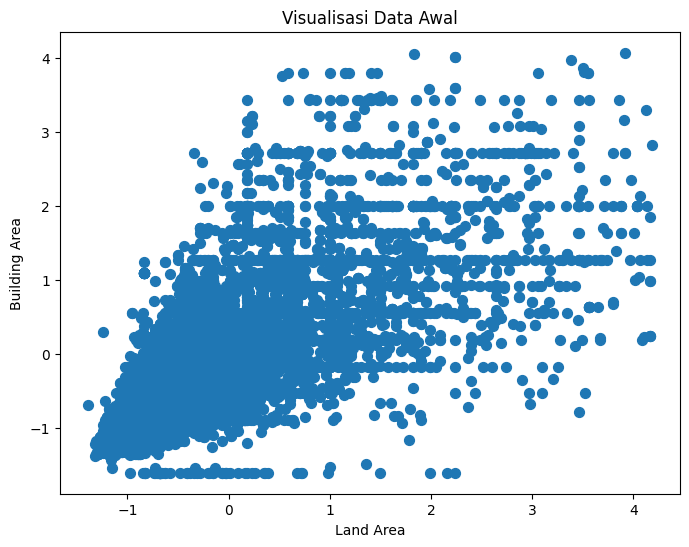

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['land_area'],
    df['building_area'],
    s=50
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('Visualisasi Data Awal')

plt.show()

### **10.6 Model DBSCAN COSINE**

In [ ]:
start_time_dbscan_cosine = time.time()

X = df.values
n = len(X)

# Mencari tetangga menggunakan Cosine Distance
neighbors = []

for data in X:

    dot_product = np.sum(X * data, axis=1)

    norm_X = np.sqrt(np.sum(X**2, axis=1))
    norm_data = np.sqrt(np.sum(data**2))

    cosine_similarity = dot_product / (norm_X * norm_data)

    cosine_distance = 1 - cosine_similarity

    tetangga = np.where(
        cosine_distance <= eps_cosine
    )[0]

    neighbors.append(tetangga)


# Menentukan Core Point
core_points = []

for tetangga in neighbors:

    if len(tetangga) >= min_samples_cosine:
        core_points.append(True)
    else:
        core_points.append(False)

core_points = np.array(core_points)


# Inisialisasi label
labels = np.full(n, -1)

cluster = 0

# Membentuk cluster
for i in range(n):

    if not core_points[i] or labels[i] != -1:
        continue

    labels[i] = cluster

    queue = [i]

    while queue:

        p = queue.pop(0)

        if not core_points[p]:
            continue

        for q in neighbors[p]:

            if labels[q] == -1:

                labels[q] = cluster
                queue.append(q)

    cluster += 1


y_dbscan_cosine = labels

end_time_dbscan_cosine = time.time()

### **10.7 Visualisasi Hasil Clustering DBSCAN Cosine**

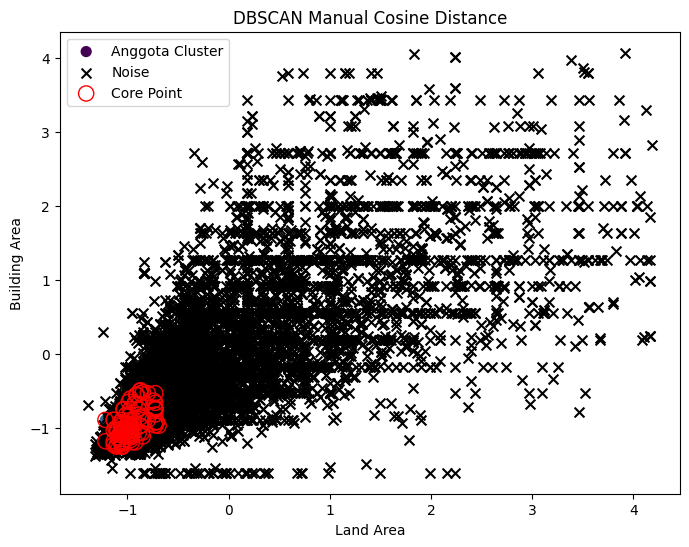

In [ ]:
plt.figure(figsize=(8,6))

# Noise
noise = y_dbscan_cosine == -1

# Anggota cluster
plt.scatter(
    df['land_area'][~noise],
    df['building_area'][~noise],
    c=y_dbscan_cosine[~noise],
    s=50,
    cmap='viridis',
    label='Anggota Cluster'
)

# Noise
plt.scatter(
    df['land_area'][noise],
    df['building_area'][noise],
    c='black',
    marker='x',
    s=50,
    label='Noise'
)

# Core Point
plt.scatter(
    df['land_area'][core_points],
    df['building_area'][core_points],
    facecolors='none',
    edgecolors='red',
    s=120,
    label='Core Point'
)

plt.xlabel('Land Area')
plt.ylabel('Building Area')
plt.title('DBSCAN Manual Cosine Distance')

plt.legend()
plt.show()

### **10.8 Evaluasi DBSCANN Cosine**

In [ ]:
# Execution time
execution_time_dbscan_cosine = (end_time_dbscan_cosine - start_time_dbscan_cosine)

# Jumlah cluster
n_cluster_dbscan_cosine = len(set(y_dbscan_cosine)) - (1 if -1 in y_dbscan_cosine else 0)

# Jumlah noise
n_noise_dbscan_cosine = np.sum(y_dbscan_cosine == -1)

# Data yang bukan noise
mask_cosine = y_dbscan_cosine != -1

X_cluster_cosine = X[mask_cosine]
labels_cluster_cosine = y_dbscan_cosine[mask_cosine]

# Evaluasi
if len(set(labels_cluster_cosine)) > 1:

    silhouette_dbscan_cosine = silhouette_score(
        X_cluster_cosine,
        labels_cluster_cosine,
        metric='cosine'
    )

    dbi_dbscan_cosine = davies_bouldin_score(
        X_cluster_cosine,
        labels_cluster_cosine
    )

    ch_dbscan_cosine = calinski_harabasz_score(
        X_cluster_cosine,
        labels_cluster_cosine
    )

else:

    silhouette_dbscan_cosine = np.nan
    dbi_dbscan_cosine = np.nan
    ch_dbscan_cosine = np.nan

### **10.9 Hasil Evaluasi DBSCAN Cosine**

In [ ]:
hasil_dbscan_cosine = pd.DataFrame({

    'Metode': ['DBSCAN Cosine'],

    'Jumlah Cluster': [n_cluster_dbscan_cosine],

    'Jumlah Noise': [n_noise_dbscan_cosine],

    'Silhouette': [silhouette_dbscan_cosine],

    'DBI': [dbi_dbscan_cosine],

    'CHI': [ch_dbscan_cosine],

    'Execution Time': [execution_time_dbscan_cosine]

})

print("=" * 80)

print("TABEL EVALUASI DBSCAN COSINE DISTANCE")

print("=" * 80)

print(hasil_dbscan_cosine.to_string(index=False))

TABEL EVALUASI DBSCAN COSINE DISTANCE
       Metode  Jumlah Cluster  Jumlah Noise  Silhouette      DBI         CHI  Execution Time
DBSCAN Cosine               4          7752    0.850334 0.576862 1006.455459        2.947747


# **11. KLASTERISASI HIERARKI - EUCLIDEAN DISTANCE**

### **11.1 Penentuan Jumlah Klaster dengan Dendrogram**

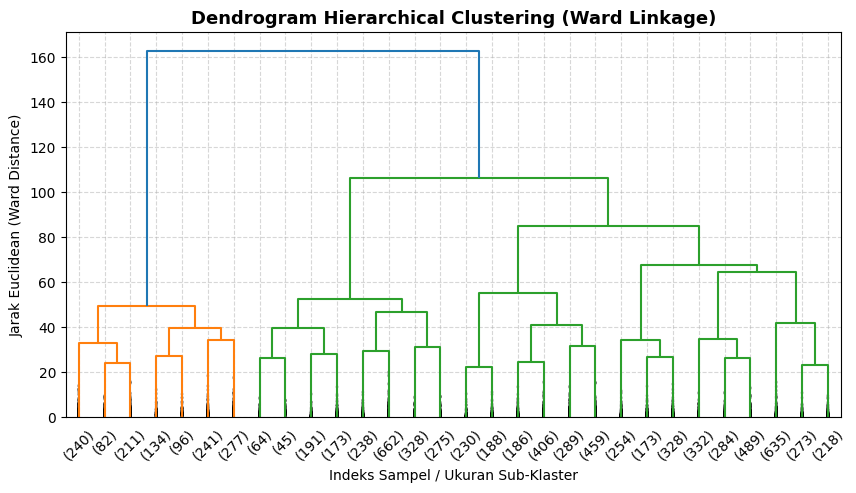

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Menghitung matriks jarak berjenjang (Ward's method meminimalkan variansi dalam klaster)
linkage_matrix = linkage(df, method='ward', metric='euclidean')

plt.figure(figsize=(10, 5))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,  # Menampilkan 30 percabangan puncak teratas
    leaf_rotation=45.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage)', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Sampel / Ukuran Sub-Klaster')
plt.ylabel('Jarak Euclidean (Ward Distance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **11.2 Evaluasi Nilai Klaster Optimal ($k = 2$ s.d. $k = 5$)**

In [ ]:
from sklearn.cluster import AgglomerativeClustering

for k in range(2, 6):
    agg_test = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels_test = agg_test.fit_predict(df)
    score_sil = silhouette_score(df, labels_test)
    print(f"k = {k}, Silhouette Score = {score_sil:.4f}")

k = 2, Silhouette Score = 0.3020
k = 3, Silhouette Score = 0.1243
k = 4, Silhouette Score = 0.1125
k = 5, Silhouette Score = 0.0962


### **11.3 Pelatihan Model Final Agglomerative Clustering ($k = 2$)**

In [ ]:
start_time_hierarchical = time.time()

linkage_matrix = linkage(df, method='ward', metric='euclidean')

X = df.values
n_samples = len(X)
k_target = 2

# Pada matriks linkage (N-1 langkah), baris terakhir [-1] adalah percabangan puncak (root)
# yang menggabungkan 2 klaster utama terakhir.
# Anak cabang puncak berada di indeks 0 dan indeks 1 pada baris terakhir linkage_matrix.
node_left = int(linkage_matrix[-1, 0])
node_right = int(linkage_matrix[-1, 1])

# Fungsi penelusuran manual (DFS/Stack) untuk mengumpulkan indeks anggota setiap klaster
def cari_anggota_klaster(node, Z, n):
    anggota = []
    stack = [node]
    while stack:
        curr = stack.pop()
        if curr < n:
            anggota.append(curr)
        else:
            left_child = int(Z[curr - n, 0])
            right_child = int(Z[curr - n, 1])
            stack.append(left_child)
            stack.append(right_child)
    return anggota

# Menelusuri seluruh anggota untuk Klaster 0 dan Klaster 1 secara manual
anggota_klaster_0 = cari_anggota_klaster(node_left, linkage_matrix, n_samples)
anggota_klaster_1 = cari_anggota_klaster(node_right, linkage_matrix, n_samples)

# Memberikan label klaster manual ke setiap baris data
y_hierarchical = np.zeros(n_samples, dtype=int)
y_hierarchical[anggota_klaster_1] = 1

# Menghitung durasi eksekusi
execution_time_hierarchical = time.time() - start_time_hierarchical

n_clusters_hierarchical = len(set(y_hierarchical))
print(f"Jumlah Klaster Terbentuk : {n_clusters_hierarchical}")
print("Distribusi per Klaster   :")
print(pd.Series(y_hierarchical).value_counts().sort_index())
print(f"Waktu Eksekusi (Manual)  : {execution_time_hierarchical:.4f} detik")

Jumlah Klaster Terbentuk : 2
Distribusi per Klaster   :
0    1281
1    6720
Name: count, dtype: int64
Waktu Eksekusi (Manual)  : 3.6068 detik


### **11.4 Visualisasi Hasil Klasterisasi Hierarki**

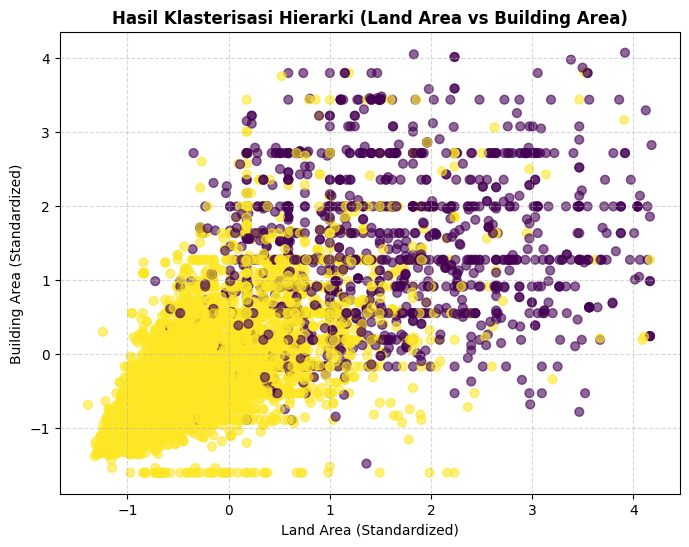

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df['land_area'],
    df['building_area'],
    c=y_hierarchical,
    s=40,
    cmap='viridis',
    alpha=0.6
)
plt.xlabel('Land Area (Standardized)')
plt.ylabel('Building Area (Standardized)')
plt.title('Hasil Klasterisasi Hierarki (Land Area vs Building Area)', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **11.5 Evaluasi Metrik Model Hierarkis**

In [ ]:
sil_hierarchical = silhouette_score(df, y_hierarchical)
dbi_hierarchical = davies_bouldin_score(df, y_hierarchical)
chi_hierarchical = calinski_harabasz_score(df, y_hierarchical)

hasil_hierarchical = pd.DataFrame({
    'Metode': ['Hierarchical'],
    'Linkage': ['Ward'],
    'Jumlah Cluster': [n_clusters_hierarchical],
    'Silhouette': [sil_hierarchical],
    'DBI': [dbi_hierarchical],
    'CHI': [chi_hierarchical],
    'Execution Time': [execution_time_hierarchical]
})

print("=" * 85)
print("TABEL EVALUASI KLASTERISASI HIERARKI")
print("=" * 85)
print(hasil_hierarchical.to_string(index=False))

TABEL EVALUASI KLASTERISASI HIERARKI
      Metode Linkage  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time
Hierarchical    Ward               2    0.302015 1.459941 2091.680394        3.606776


# **12. KLASTERISASI HIERARKI - MANHATTAN DISTANCE**

### **12.1 Penentuan Jumlah Klaster dengan Dendrogram**

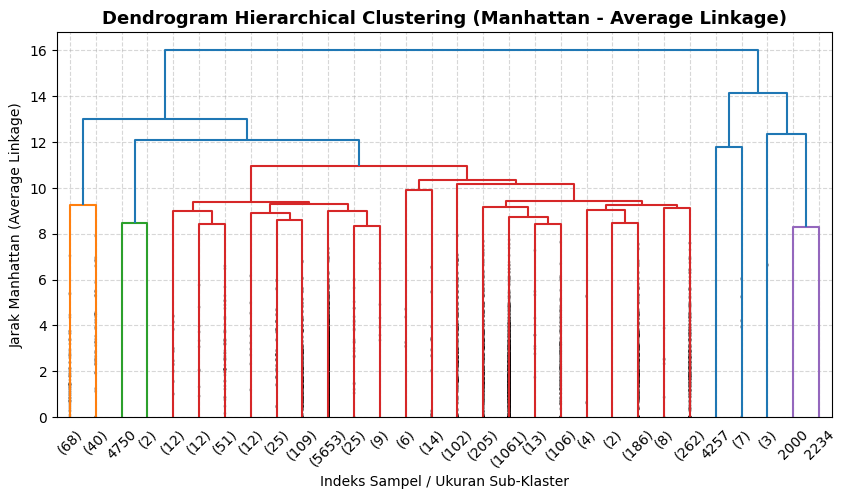

In [ ]:
linkage_manhattan = linkage(df, method='average', metric='cityblock')

plt.figure(figsize=(10, 5))
dendrogram(
    linkage_manhattan,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=45.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title('Dendrogram Hierarchical Clustering (Manhattan - Average Linkage)', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Sampel / Ukuran Sub-Klaster')
plt.ylabel('Jarak Manhattan (Average Linkage)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### **12.2 Evaluasi Nilai Klaster ($k = 2$ s.d. $k = 5$) Manhattan**

In [ ]:
from scipy.cluster.hierarchy import fcluster

for k in range(2, 6):
    labels_test = fcluster(linkage_manhattan, t=k, criterion='maxclust') - 1

    if len(set(labels_test)) > 1:
        score_sil = silhouette_score(df, labels_test, metric='manhattan')
    else:
        score_sil = np.nan

    ukuran = np.bincount(labels_test).tolist()
    print(f"k = {k}, Silhouette Score = {score_sil:.4f}, Ukuran Klaster = {ukuran}")


k = 2, Silhouette Score = 0.4353, Ukuran Klaster = [7988, 13]
k = 3, Silhouette Score = 0.3872, Ukuran Klaster = [7988, 8, 5]
k = 4, Silhouette Score = 0.2835, Ukuran Klaster = [108, 7880, 8, 5]
k = 5, Silhouette Score = 0.2706, Ukuran Klaster = [108, 7880, 8, 3, 2]


### **12.3 Pelatihan Model Final Hierarchical Manhattan ($k = 2$)**

In [ ]:
start_time_linkage_manhattan = time.time()

linkage_manhattan = linkage(df, method='average', metric='cityblock')

X = df.values
n_samples = len(X)
k_target = 2

node_left = int(linkage_manhattan[-1, 0])
node_right = int(linkage_manhattan[-1, 1])

anggota_klaster_0 = cari_anggota_klaster(node_left, linkage_manhattan, n_samples)
anggota_klaster_1 = cari_anggota_klaster(node_right, linkage_manhattan, n_samples)

y_hierarchical_manhattan = np.zeros(n_samples, dtype=int)
y_hierarchical_manhattan[anggota_klaster_1] = 1

execution_time_hierarchical_manhattan = time.time() - start_time_linkage_manhattan

n_clusters_hierarchical_manhattan = len(set(y_hierarchical_manhattan))
print(f"Jumlah Klaster Terbentuk : {n_clusters_hierarchical_manhattan}")
print("Distribusi per Klaster   :")
print(pd.Series(y_hierarchical_manhattan).value_counts().sort_index())
print(f"Waktu Eksekusi (Manhattan)  : {execution_time_hierarchical_manhattan:.4f} detik")

Jumlah Klaster Terbentuk : 2
Distribusi per Klaster   :
0    7988
1      13
Name: count, dtype: int64
Waktu Eksekusi (Manhattan)  : 3.7955 detik


### **12.4 Visualisasi Hasil Klasterisasi Hierarki Manhattan**

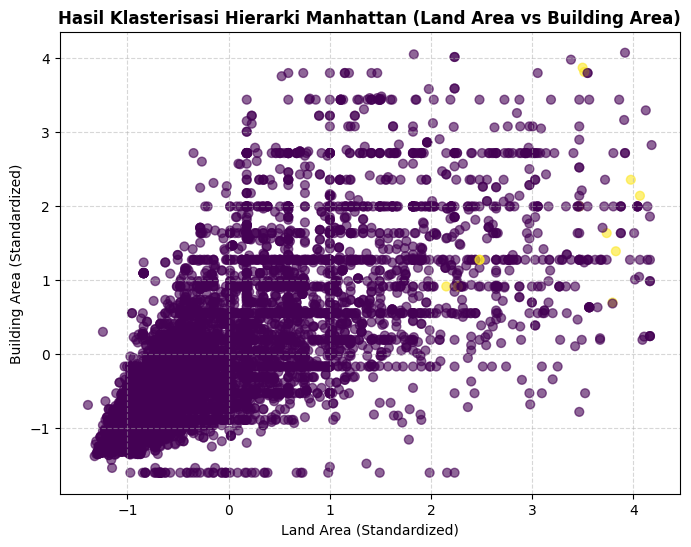

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df['land_area'],
    df['building_area'],
    c=y_hierarchical_manhattan,
    s=40,
    cmap='viridis',
    alpha=0.6
)
plt.xlabel('Land Area (Standardized)')
plt.ylabel('Building Area (Standardized)')
plt.title('Hasil Klasterisasi Hierarki Manhattan (Land Area vs Building Area)', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **12.5 Evaluasi Metrik Model Hierarki Manhattan**

In [ ]:
sil_hierarchical_manhattan = silhouette_score(df, y_hierarchical_manhattan, metric='manhattan')
dbi_hierarchical_manhattan = davies_bouldin_score(df, y_hierarchical_manhattan)
chi_hierarchical_manhattan = calinski_harabasz_score(df, y_hierarchical_manhattan)

hasil_hierarchical_manhattan = pd.DataFrame({
    'Metode': ['Hierarchical Manhattan'],
    'Linkage': ['Average'],
    'Metric': ['Manhattan'],
    'Jumlah Cluster': [n_clusters_hierarchical_manhattan],
    'Silhouette': [sil_hierarchical_manhattan],
    'DBI': [dbi_hierarchical_manhattan],
    'CHI': [chi_hierarchical_manhattan],
    'Execution Time': [execution_time_hierarchical_manhattan]
})

print("=" * 85)
print("TABEL EVALUASI KLASTERISASI HIERARKI MANHATTAN")
print("=" * 85)
print(hasil_hierarchical_manhattan.to_string(index=False))

TABEL EVALUASI KLASTERISASI HIERARKI MANHATTAN
                Metode Linkage    Metric  Jumlah Cluster  Silhouette      DBI      CHI  Execution Time
Hierarchical Manhattan Average Manhattan               2    0.435278 1.313969 38.43174        3.795459


# **13 KLASTERISASI HIERARKI - COSINE**

### **13.1 Penentuan Jumlah Klaster dengan Dendrogram**

Jumlah baris dengan norm 0 : 0


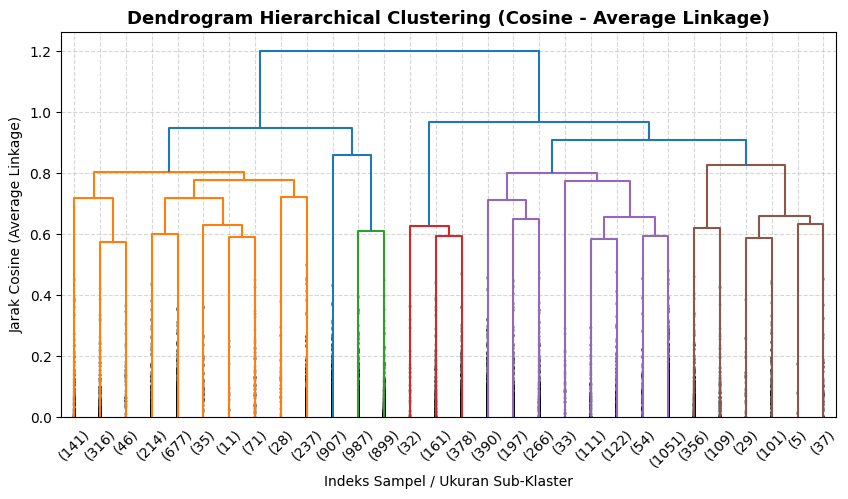

In [ ]:
print("Jumlah baris dengan norm 0 :", int((np.linalg.norm(df.values, axis=1) == 0).sum()))

linkage_cosine = linkage(df, method='average', metric='cosine')

plt.figure(figsize=(10, 5))
dendrogram(
    linkage_cosine,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=45.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title('Dendrogram Hierarchical Clustering (Cosine - Average Linkage)', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Sampel / Ukuran Sub-Klaster')
plt.ylabel('Jarak Cosine (Average Linkage)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **13.2 Evaluasi Nilai Klaster ($k = 2$ s.d. $k = 5$) Cosine**

In [ ]:
from scipy.cluster.hierarchy import fcluster

for k in range(2, 6):
    labels_test = fcluster(linkage_cosine, t=k, criterion='maxclust') - 1

    if len(set(labels_test)) > 1:
        score_sil = silhouette_score(df, labels_test, metric='cosine')
    else:
        score_sil = np.nan

    ukuran = np.bincount(labels_test).tolist()
    print(f"k = {k}, Silhouette Score = {score_sil:.4f}, Ukuran Klaster = {ukuran}")

k = 2, Silhouette Score = 0.3172, Ukuran Klaster = [4569, 3432]
k = 3, Silhouette Score = 0.1959, Ukuran Klaster = [4569, 571, 2861]
k = 4, Silhouette Score = 0.2005, Ukuran Klaster = [1776, 2793, 571, 2861]
k = 5, Silhouette Score = 0.1869, Ukuran Klaster = [1776, 2793, 571, 2224, 637]


### **13.3 Pelatihan Model Final Hierarchical Cosine ($k = 2$)**

In [ ]:
start_time_hierarchical_cosine = time.time()

linkage_cosine = linkage(df, method='average', metric='cosine')

X = df.values
n_samples = len(X)
k_target = 2

node_left = int(linkage_cosine[-1, 0])
node_right = int(linkage_cosine[-1, 1])

anggota_klaster_0 = cari_anggota_klaster(node_left, linkage_cosine, n_samples)
anggota_klaster_1 = cari_anggota_klaster(node_right, linkage_cosine, n_samples)

y_hierarchical_cosine = np.zeros(n_samples, dtype=int)
y_hierarchical_cosine[anggota_klaster_1] = 1

execution_time_hierarchical_cosine = time.time() - start_time_hierarchical_cosine

n_clusters_hierarchical_cosine = len(set(y_hierarchical_cosine))
print(f"Jumlah Klaster Terbentuk : {n_clusters_hierarchical_cosine}")
print("Distribusi per Klaster   :")
print(pd.Series(y_hierarchical_cosine).value_counts().sort_index())
print(f"Waktu Eksekusi (Cosine)  : {execution_time_hierarchical_cosine:.4f} detik")

Jumlah Klaster Terbentuk : 2
Distribusi per Klaster   :
0    4569
1    3432
Name: count, dtype: int64
Waktu Eksekusi (Cosine)  : 4.2260 detik


### **13.4 Visualisasi Hasil Klasterisasi Hierarki Cosine**

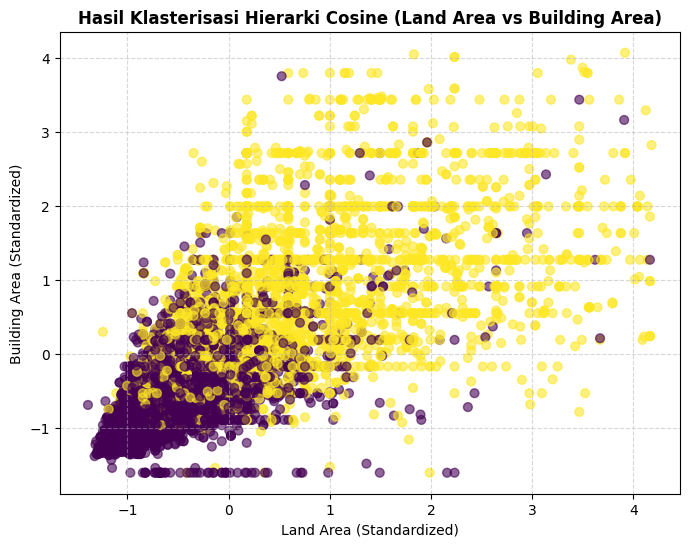

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df['land_area'],
    df['building_area'],
    c=y_hierarchical_cosine,
    s=40,
    cmap='viridis',
    alpha=0.6
)
plt.xlabel('Land Area (Standardized)')
plt.ylabel('Building Area (Standardized)')
plt.title('Hasil Klasterisasi Hierarki Cosine (Land Area vs Building Area)', fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **13.5 Evaluasi Metrik Model Hierarki Cosine**

In [ ]:
sil_hierarchical_cosine = silhouette_score(df, y_hierarchical_cosine, metric='cosine')
dbi_hierarchical_cosine = davies_bouldin_score(df, y_hierarchical_cosine)
chi_hierarchical_cosine = calinski_harabasz_score(df, y_hierarchical_cosine)

hasil_hierarchical_cosine = pd.DataFrame({
    'Metode': ['Hierarchical Cosine'],
    'Linkage': ['Average'],
    'Metric': ['Cosine'],
    'Jumlah Cluster': [n_clusters_hierarchical_cosine],
    'Silhouette': [sil_hierarchical_cosine],
    'DBI': [dbi_hierarchical_cosine],
    'CHI': [chi_hierarchical_cosine],
    'Execution Time': [execution_time_hierarchical_cosine]
})

print("=" * 85)
print("TABEL EVALUASI KLASTERISASI HIERARKI COSINE")
print("=" * 85)
print(hasil_hierarchical_cosine.to_string(index=False))

TABEL EVALUASI KLASTERISASI HIERARKI COSINE
             Metode Linkage Metric  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time
Hierarchical Cosine Average Cosine               2    0.317195 1.782608 2316.044226        4.225977


# **14. HASIL AKHIR**

### **14.1 Tabel Kmeans**

In [ ]:
hasil_final_kmeans = pd.concat([
    hasil_euclidean,
    hasil_manhattan,
    hasil_cosine
])

print("=" * 80)
print("TABEL EVALUASI KMEANS")
print("=" * 80)

print(hasil_final_kmeans.to_string(index=False))

TABEL EVALUASI KMEANS
                    Metode  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time  Iterations          SSE
K-Means Eucledian Distance               2    0.272507 1.545344 2901.855067        2.348547          19 46968.791791
         K-Means Manhattan               2    0.291949 1.647277 2678.175533        1.861229           9 51096.552646
            K-Means Cosine               2    0.374234 1.632044 2783.303407        1.997009           9 47485.214675


### **14.2 Tabel DBSCAN**

In [ ]:
hasil_final_dbscan = pd.concat([
    hasil_dbscan_euclidean,
    hasil_dbscan_manhattan,
    hasil_dbscan_cosine
])

print("=" * 80)
print("TABEL EVALUASI DBSCAN")
print("=" * 80)

print(hasil_final_dbscan.to_string(index=False))

TABEL EVALUASI DBSCAN
          Metode  Jumlah Cluster  Jumlah Noise  Silhouette      DBI         CHI  Execution Time
DBSCAN Euclidean               3           488    0.323696 0.712345   43.650386        3.122118
DBSCAN Manhattan               2           123    0.433572 0.604611   18.733536        2.558322
   DBSCAN Cosine               4          7752    0.850334 0.576862 1006.455459        2.947747


### **14.3 Tabel Hierarki**

In [ ]:
hasil_final_hierarchical = pd.concat([
    hasil_hierarchical,
    hasil_hierarchical_manhattan,
    hasil_hierarchical_cosine
])

print("=" * 80)
print("TABEL EVALUASI HIERARCHICAL")
print("=" * 80)

print(hasil_final_hierarchical.to_string(index=False))

TABEL EVALUASI HIERARCHICAL
                Metode Linkage  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time    Metric
          Hierarchical    Ward               2    0.302015 1.459941 2091.680394        3.606776       NaN
Hierarchical Manhattan Average               2    0.435278 1.313969   38.431740        3.795459 Manhattan
   Hierarchical Cosine Average               2    0.317195 1.782608 2316.044226        4.225977    Cosine


### **14.3 Tabel Gabungan**

In [ ]:
# Menambahkan kolom algoritma
hasil_final_kmeans['Algoritma'] = 'K-Means'
hasil_final_dbscan['Algoritma'] = 'DBSCAN'
hasil_final_hierarchical['Algoritma'] = 'Hierarchical'

# Menggabungkan hasil K-Means, DBSCAN, dan Hierarchical
hasil_gabungan = pd.concat([
    hasil_final_kmeans,
    hasil_final_dbscan,
    hasil_final_hierarchical
], ignore_index=True)

# Menampilkan tabel gabungan
print("=" * 120)
print("TABEL EVALUASI K-MEANS, DBSCAN, DAN HIERARCHICAL")
print("=" * 120)
print(
    hasil_gabungan.drop(
        columns=['SSE', 'Linkage'],
        errors='ignore'
    ).to_string(index=False)
)

TABEL EVALUASI K-MEANS, DBSCAN, DAN HIERARCHICAL
                    Metode  Jumlah Cluster  Silhouette      DBI         CHI  Execution Time  Iterations    Algoritma  Jumlah Noise    Metric
K-Means Eucledian Distance               2    0.272507 1.545344 2901.855067        2.348547        19.0      K-Means           NaN       NaN
         K-Means Manhattan               2    0.291949 1.647277 2678.175533        1.861229         9.0      K-Means           NaN       NaN
            K-Means Cosine               2    0.374234 1.632044 2783.303407        1.997009         9.0      K-Means           NaN       NaN
          DBSCAN Euclidean               3    0.323696 0.712345   43.650386        3.122118         NaN       DBSCAN         488.0       NaN
          DBSCAN Manhattan               2    0.433572 0.604611   18.733536        2.558322         NaN       DBSCAN         123.0       NaN
             DBSCAN Cosine               4    0.850334 0.576862 1006.455459        2.947747         NaN  

### **14.4 Analisis**

Berdasarkan hasil pengujian clustering pada dataset harga rumah Jakarta, penentuan kombinasi algoritma dan metrik jarak terbaik dilakukan menggunakan metode Borda dengan mempertimbangkan lima kriteria, yaitu Silhouette, Davies-Bouldin Index (DBI), Calinski-Harabasz Index (CHI), waktu eksekusi, dan jumlah noise. Hasil perhitungan menunjukkan bahwa K-Means Cosine dan DBSCAN Cosine memperoleh skor Borda tertinggi yang sama, yaitu 26 poin. Namun, K-Means Cosine dipilih sebagai kombinasi algoritma dan metrik jarak yang direkomendasikan karena memperoleh nilai Silhouette sebesar 0,374234 dengan waktu eksekusi 3,516427 detik  serta tidak menghasilkan data noise. Sementara itu, DBSCAN Cosine memiliki nilai Silhouette lebih tinggi, yaitu 0,850334, dan waktu eksekusi 1,982656 detik, tetapi menghasilkan noise sebesar 96,89% dari seluruh data. Oleh karena itu, K-Means Cosine dinilai lebih sesuai apabila tujuan clustering adalah mengelompokkan seluruh data dengan kualitas cluster yang cukup baik


# **15 Dataset Kontrol**

### **15.1 Import Library dan Konfigurasi**

In [1]:
import os, platform, warnings
import scipy, sklearn
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import Normalizer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics.pairwise import pairwise_distances

In [3]:
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ====== SESUAIKAN DENGAN NOTEBOOK TEMPLATE ======
N_SAMPLES   = 500
BLOBS_STD   = 0.60
MOONS_NOISE = 0.05

In [4]:
METRICS = ["euclidean", "manhattan", "cosine"]
SCIPY_METRIC = {"euclidean": "euclidean", "manhattan": "cityblock", "cosine": "cosine"}
N_RUN_WAKTU = 5
OUT_DIR = "hasil_kontrol"
os.makedirs(OUT_DIR, exist_ok=True)

print("Python       :", platform.python_version())
print("numpy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scipy        :", scipy.__version__)
print("scikit-learn :", sklearn.__version__)

Python       : 3.13.16
numpy        : 2.1.3
pandas       : 2.2.3
scipy        : 1.16.3
scikit-learn : 1.6.1


### **15.2 Membuat Dataset Kontrol**

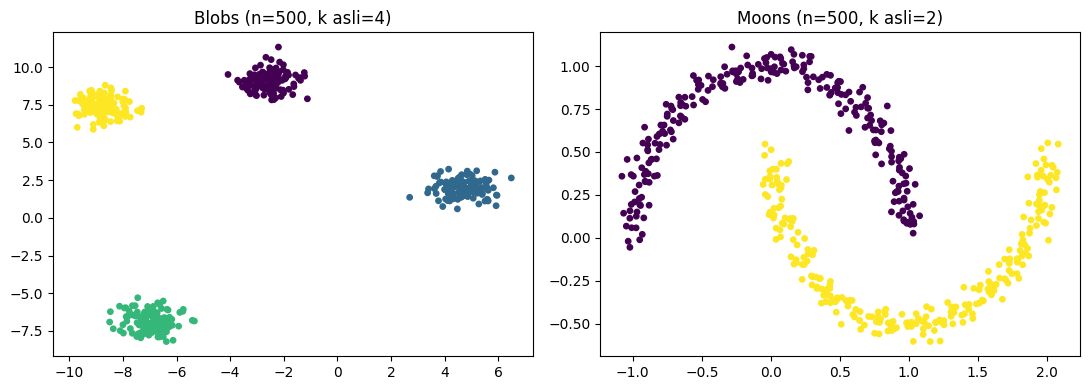

In [6]:
DATASETS = {
    "Blobs": dict(
        k=4,
        data=make_blobs(n_samples=N_SAMPLES, centers=4,
                        cluster_std=BLOBS_STD, random_state=RANDOM_STATE)),
    "Moons": dict(
        k=2,
        data=make_moons(n_samples=N_SAMPLES, noise=MOONS_NOISE,
                        random_state=RANDOM_STATE)),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nama, d) in zip(axes, DATASETS.items()):
    X, y = d["data"]
    ax.scatter(X[:, 0], X[:, 1], c=y, s=15, cmap="viridis")
    ax.set_title(f"{nama} (n={len(X)}, k asli={d['k']})")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/00_dataset_kontrol.png", dpi=150)
plt.show()

### **15.3 Praproses Data**

In [ ]:
def praproses(X, metric):
    if metric == "cosine":
        return Normalizer(norm="l2").fit_transform(X)
    return StandardScaler().fit_transform(X)

for nama, d in DATASETS.items():
    X, y = d["data"]
    d["X"], d["y"] = X, y
    d["Xp"] = {m: praproses(X, m) for m in METRICS}
    print(nama, "| shape:", X.shape, "| missing:", int(np.isnan(X).sum()))

Blobs | shape: (500, 2) | missing: 0
Moons | shape: (500, 2) | missing: 0


### **15.4 Elbow dan Silhouette (K-Means)**

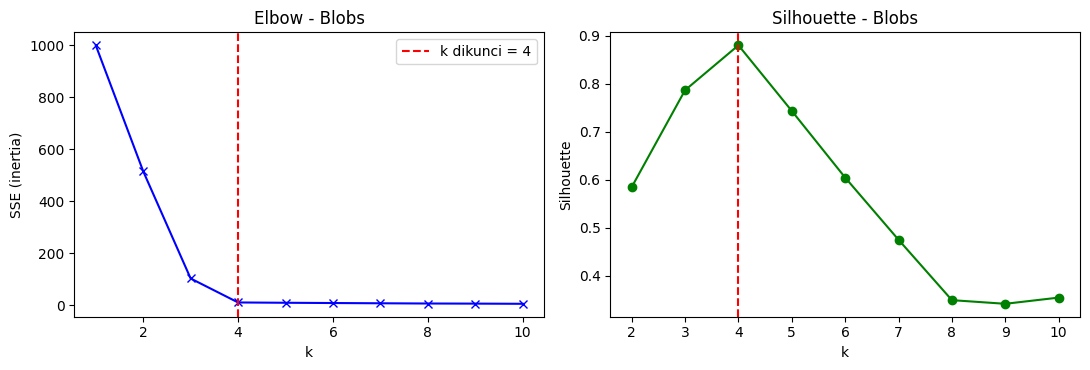

Blobs: k terbaik menurut silhouette = 4, k yang dipakai = 4


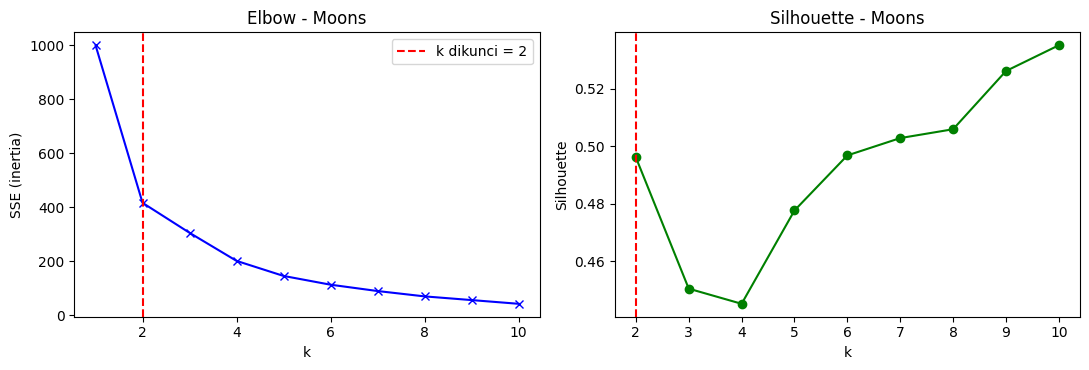

Moons: k terbaik menurut silhouette = 10, k yang dipakai = 2


In [ ]:
for nama, d in DATASETS.items():
    Xs = d["Xp"]["euclidean"]
    ks = range(1, 11)
    sse, sil = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
        sse.append(km.inertia_)
        sil.append(silhouette_score(Xs, km.labels_) if k >= 2 else np.nan)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(list(ks), sse, "bx-"); ax[0].axvline(d["k"], color="r", ls="--", label=f"k dikunci = {d['k']}")
    ax[0].set_title(f"Elbow - {nama}"); ax[0].set_xlabel("k"); ax[0].set_ylabel("SSE (inertia)"); ax[0].legend()
    ax[1].plot(list(ks), sil, "go-"); ax[1].axvline(d["k"], color="r", ls="--")
    ax[1].set_title(f"Silhouette - {nama}"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/01_elbow_silhouette_{nama.lower()}.png", dpi=150)
    plt.show()
    print(f"{nama}: k terbaik menurut silhouette = {2 + int(np.nanargmax(sil[1:]))}, k yang dipakai = {d['k']}")

### **15.5 K-Distance Graph dan Eps (DBSCAN)**

In [ ]:
EPS_OVERRIDE = {
    # contoh: ("Moons", "cosine"): 0.02,
}

def k_distance(Xp, metric, k):
    algo = "brute" if metric == "cosine" else "auto"
    nn = NearestNeighbors(n_neighbors=k, metric=metric, algorithm=algo).fit(Xp)
    dist, _ = nn.kneighbors(Xp)
    return np.sort(dist[:, -1])

def pilih_eps(kd):
    w = max(5, len(kd) // 50)
    s = np.convolve(kd, np.ones(w) / w, mode="same")[w:-w]
    idx = int(np.argmax(np.gradient(np.gradient(s))))
    return float(s[idx]), idx + w

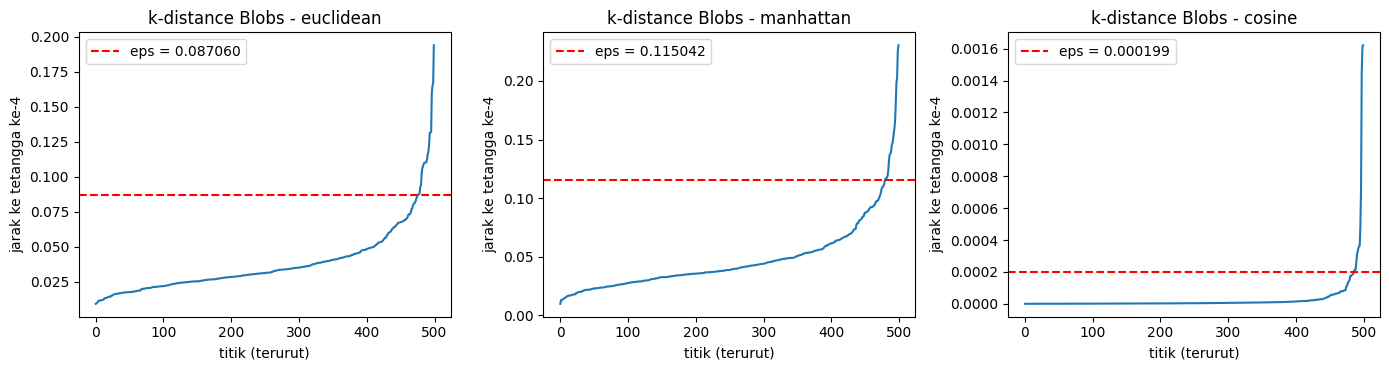

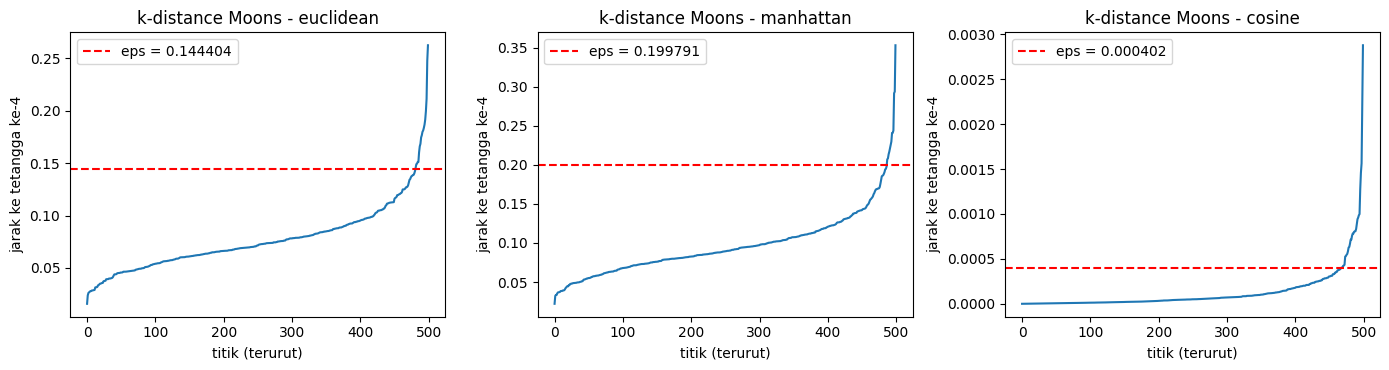

In [ ]:
for nama, d in DATASETS.items():
    dim = d["X"].shape[1]
    d["min_samples"] = max(4, 2 * dim)
    d["eps"] = {}
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    for ax, m in zip(axes, METRICS):
        kd = k_distance(d["Xp"][m], m, d["min_samples"])
        eps, idx = pilih_eps(kd)
        eps = EPS_OVERRIDE.get((nama, m), eps)
        d["eps"][m] = eps
        ax.plot(kd)
        ax.axhline(eps, color="r", ls="--", label=f"eps = {eps:.6f}")
        ax.set_title(f"k-distance {nama} - {m}")
        ax.set_xlabel("titik (terurut)"); ax.set_ylabel(f"jarak ke tetangga ke-{d['min_samples']}")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/02_kdistance_{nama.lower()}.png", dpi=150)
    plt.show()

In [ ]:
print(nama, "| min_samples =", d["min_samples"], "| eps =", {m: round(v, 6) for m, v in d["eps"].items()})

Moons | min_samples = 4 | eps = {'euclidean': 0.144404, 'manhattan': 0.199791, 'cosine': 0.000402}


### **15.6 Dendrogram (Hierarchical, Average Linkage)**

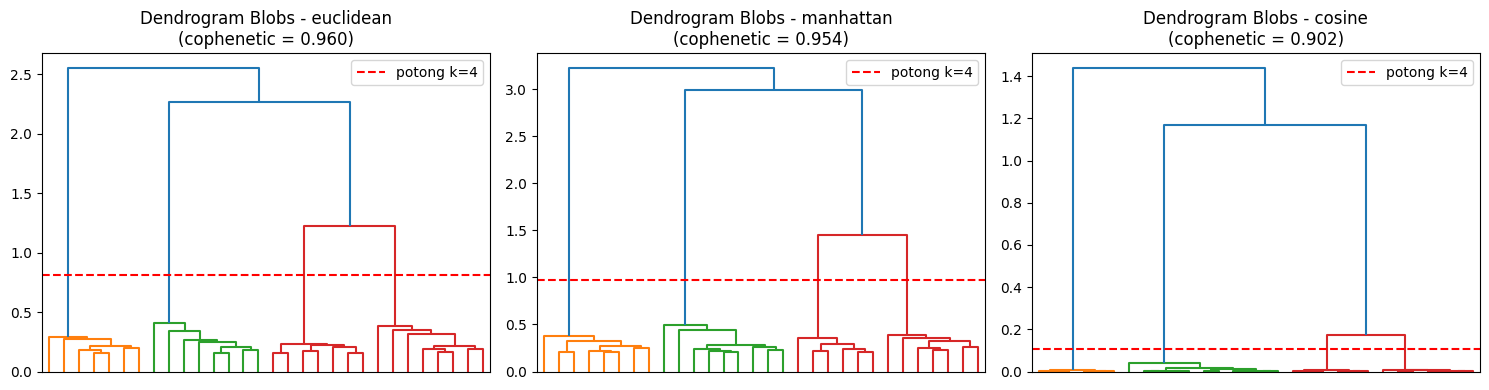

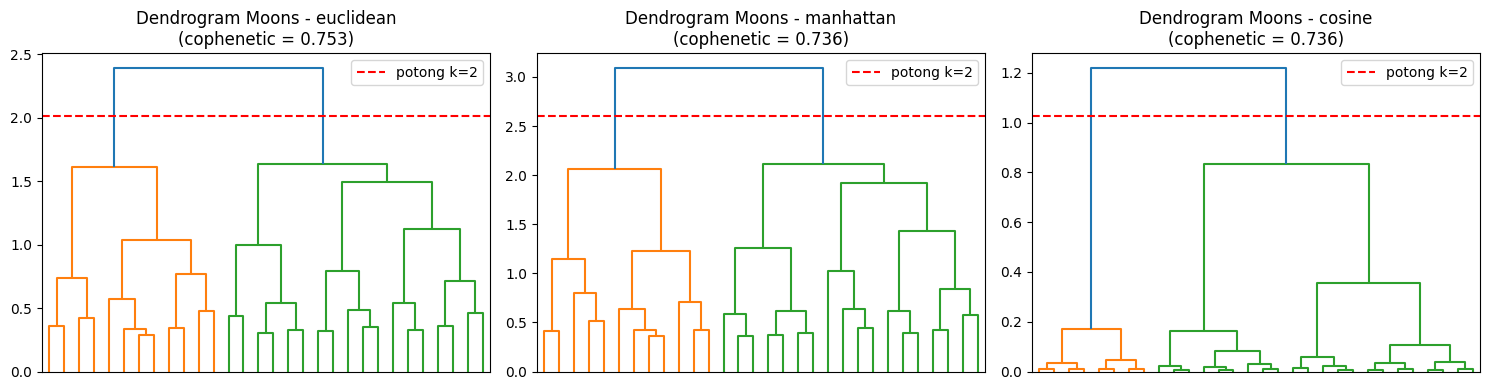

In [ ]:
for nama, d in DATASETS.items():
    k = d["k"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    d["cophenetic"] = {}
    for ax, m in zip(axes, METRICS):
        Xp = d["Xp"][m]
        Z = linkage(Xp, method="average", metric=SCIPY_METRIC[m])
        c, _ = cophenet(Z, pdist(Xp, metric=SCIPY_METRIC[m]))
        d["cophenetic"][m] = c
        cut = (Z[-k, 2] + Z[-(k - 1), 2]) / 2 if k >= 2 else Z[-1, 2]
        dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, ax=ax)
        ax.axhline(cut, color="r", ls="--", label=f"potong k={k}")
        ax.set_title(f"Dendrogram {nama} - {m}\n(cophenetic = {c:.3f})")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/03_dendrogram_{nama.lower()}.png", dpi=150)
    plt.show()

### **15.7 Fungsi Clustering dan Evaluasi**

In [ ]:
def kmedians(X, k, n_init=10, max_iter=300, seed=RANDOM_STATE):
    """K-Medians (jarak Manhattan, centroid = median)."""
    rng = np.random.RandomState(seed)
    best = None
    for _ in range(n_init):
        cent = X[rng.choice(len(X), k, replace=False)]
        for _ in range(max_iter):
            lab = pairwise_distances(X, cent, metric="manhattan").argmin(axis=1)
            new = np.array([np.median(X[lab == j], axis=0) if np.any(lab == j) else cent[j]
                            for j in range(k)])
            if np.allclose(new, cent):
                break
            cent = new
        dist = pairwise_distances(X, cent, metric="manhattan")
        lab = dist.argmin(axis=1)
        cost = dist[np.arange(len(X)), lab].sum()
        if best is None or cost < best[0]:
            best = (cost, lab)
    return best[1]

In [ ]:
def buat_fungsi(algo, metric, Xp, k, eps, min_samples):
    if algo == "K-Means*":
        if metric == "manhattan":
            return lambda: kmedians(Xp, k)
        # euclidean = KMeans biasa; cosine = spherical k-means (data sudah dinormalisasi L2)
        return lambda: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xp)
    if algo == "DBSCAN":
        algorithm = "brute" if metric == "cosine" else "auto"
        return lambda: DBSCAN(eps=eps, min_samples=min_samples,
                              metric=metric, algorithm=algorithm).fit_predict(Xp)
    if algo == "Hierarchical":
        return lambda: AgglomerativeClustering(n_clusters=k, metric=metric,
                                               linkage="average").fit_predict(Xp)

In [ ]:
def waktu_ms(fn, n=N_RUN_WAKTU):
    ts, out = [], None
    for _ in range(n):
        t = time.perf_counter()
        out = fn()
        ts.append((time.perf_counter() - t) * 1000)
    return out, float(np.mean(ts))

In [ ]:
def evaluasi(Xp, y_true, labels, metric):
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    pct_noise = 100 * (~mask).mean()
    if n_cl >= 2 and mask.sum() > n_cl:
        sil = silhouette_score(Xp[mask], labels[mask], metric=metric)
        dbi = davies_bouldin_score(Xp[mask], labels[mask])
    else:
        sil, dbi = np.nan, np.nan
    return dict(k=n_cl, pct_noise=pct_noise, sil=sil, dbi=dbi,
                ari=adjusted_rand_score(y_true, labels),
                nmi=normalized_mutual_info_score(y_true, labels))

### **15.8 Menjalankan 9 Konfigurasi**

In [ ]:
ALGOS = ["K-Means*", "DBSCAN", "Hierarchical"]
for nama, d in DATASETS.items():
    rows, d["labels"] = [], {}
    for algo in ALGOS:
        for m in METRICS:
            fn = buat_fungsi(algo, m, d["Xp"][m], d["k"], d["eps"][m], d["min_samples"])
            labels, t_ms = waktu_ms(fn)
            d["labels"][(algo, m)] = labels
            r = evaluasi(d["Xp"][m], d["y"], labels, m)
            rows.append({"Algoritma": algo, "Metrik": m.capitalize(), "k": r["k"],
                         "% noise": round(r["pct_noise"], 2),
                         "Silhouette": round(r["sil"], 4), "DBI": round(r["dbi"], 4),
                         "ARI": round(r["ari"], 4), "NMI": round(r["nmi"], 4),
                         "Waktu (ms)": round(t_ms, 2)})
    d["tabel"] = pd.DataFrame(rows)
print("Selesai.")

Selesai.


### **15.9 Tabel Ringkasan Hasil**

In [ ]:
pd.set_option("display.width", 200)
for nama, d in DATASETS.items():
    print("=" * 95)
    print(f"DATASET KONTROL - {nama.upper()}  (n={len(d['X'])}, k asli={d['k']})")
    print("=" * 95)
    display(d["tabel"])
    d["tabel"].to_csv(f"{OUT_DIR}/tabel_hasil_{nama.lower()}.csv", index=False)

DATASET KONTROL - BLOBS  (n=500, k asli=4)


,Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,Waktu (ms)
0,K-Means*,Euclidean,4,0.0,0.8801,0.1679,1.0000,1.0000,22.47
1,K-Means*,Manhattan,4,0.0,0.8749,0.1679,1.0000,1.0000,126.85
2,K-Means*,Cosine,4,0.0,0.9863,0.1186,1.0000,1.0000,42.34
3,DBSCAN,Euclidean,4,2.8,0.8843,0.1630,0.9617,0.9447,12.92
4,DBSCAN,Manhattan,4,2.0,0.8785,0.1634,0.9727,0.9568,18.82
5,DBSCAN,Cosine,6,1.0,0.8172,0.2552,0.9588,0.9501,30.80
6,Hierarchical,Euclidean,4,0.0,0.8801,0.1679,1.0000,1.0000,26.87
7,Hierarchical,Manhattan,4,0.0,0.8749,0.1679,1.0000,1.0000,25.73
8,Hierarchical,Cosine,4,0.0,0.9863,0.1186,1.0000,1.0000,22.01


DATASET KONTROL - MOONS  (n=500, k asli=2)


,Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,Waktu (ms)
0,K-Means*,Euclidean,2,0.0,0.4961,0.8107,0.4451,0.3516,36.24
1,K-Means*,Manhattan,2,0.0,0.4907,0.8166,0.4505,0.3569,156.89
2,K-Means*,Cosine,2,0.0,0.7758,0.6233,0.3351,0.2715,28.55
3,DBSCAN,Euclidean,3,1.6,0.2634,1.1280,0.7995,0.7955,14.94
4,DBSCAN,Manhattan,2,1.0,0.3869,1.0033,0.9802,0.9589,10.46
5,DBSCAN,Cosine,17,4.2,0.4300,0.4170,0.2670,0.2473,15.25
6,Hierarchical,Euclidean,2,0.0,0.4590,0.8547,0.6652,0.6389,17.25
7,Hierarchical,Manhattan,2,0.0,0.4538,0.8547,0.6652,0.6389,8.83
8,Hierarchical,Cosine,2,0.0,0.6886,0.6591,0.5174,0.4179,9.18


In [ ]:
print("K-Means-Manhattan = K-Medians; K-Means-Cosine = spherical k-means.")
print("ARI/NMI: noise dihitung sebagai satu label; Silhouette/DBI tanpa titik noise.")

K-Means-Manhattan = K-Medians; K-Means-Cosine = spherical k-means.
ARI/NMI: noise dihitung sebagai satu label; Silhouette/DBI tanpa titik noise.


### **15.10 Cophenetic Correlation dan Pembanding Ward**

In [ ]:
for nama, d in DATASETS.items():
    Xs = d["Xp"]["euclidean"]
    lab_ward, t_ward = waktu_ms(lambda: AgglomerativeClustering(
        n_clusters=d["k"], linkage="ward").fit_predict(Xs))
    r = evaluasi(Xs, d["y"], lab_ward, "euclidean")
    print(f"--- {nama} ---")
    print("Cophenetic correlation (average linkage):",
          {m.capitalize(): round(float(v), 4) for m, v in d["cophenetic"].items()})
    print(f"Ward (Euclidean, pembanding): Sil={r['sil']:.4f} DBI={r['dbi']:.4f} "
          f"ARI={r['ari']:.4f} NMI={r['nmi']:.4f} Waktu={t_ward:.2f} ms\n")

--- Blobs ---
Cophenetic correlation (average linkage): {'Euclidean': 0.96, 'Manhattan': 0.9539, 'Cosine': 0.9018}
Ward (Euclidean, pembanding): Sil=0.8801 DBI=0.1679 ARI=1.0000 NMI=1.0000 Waktu=24.43 ms

--- Moons ---
Cophenetic correlation (average linkage): {'Euclidean': 0.7532, 'Manhattan': 0.7358, 'Cosine': 0.736}
Ward (Euclidean, pembanding): Sil=0.4630 DBI=0.8507 ARI=0.6587 NMI=0.6338 Waktu=26.16 ms



### **15.11 Visualisasi Grid 3x3**

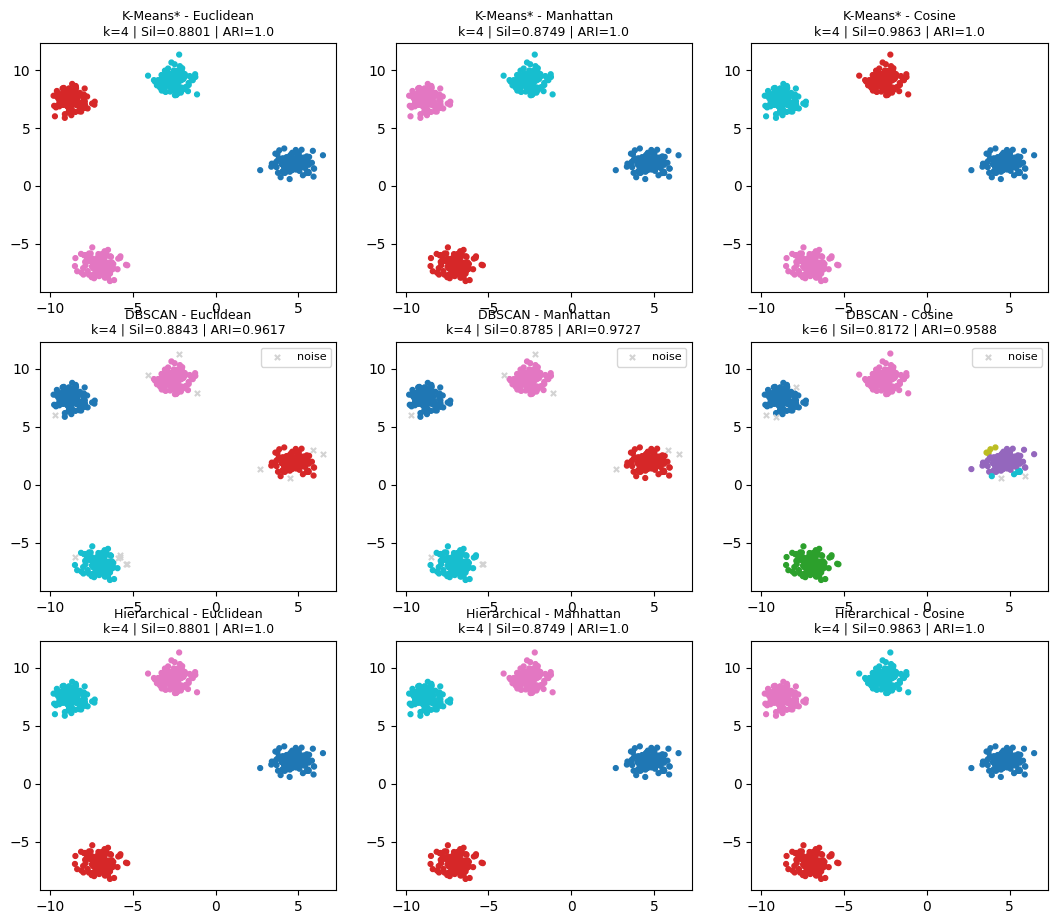

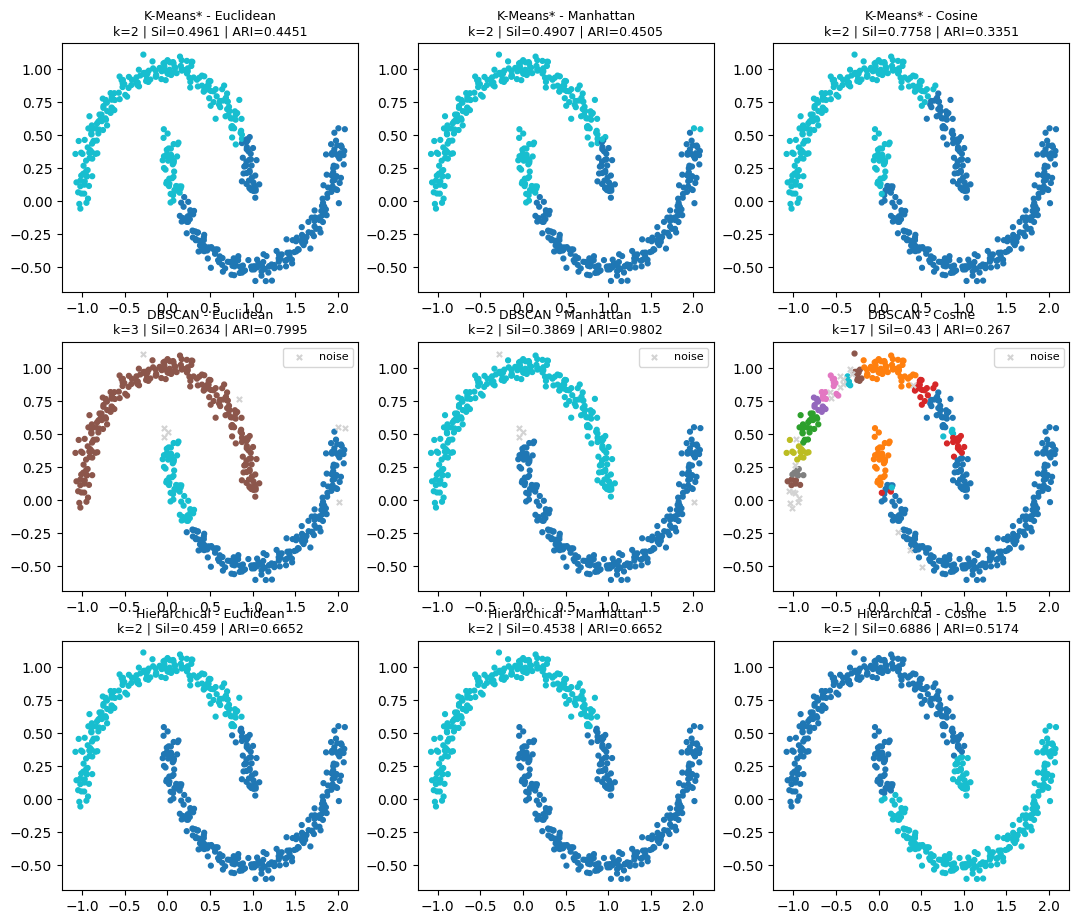

In [ ]:
for nama, d in DATASETS.items():
    X = d["X"]
    fig, axes = plt.subplots(3, 3, figsize=(13, 11))
    for i, algo in enumerate(ALGOS):
        for j, m in enumerate(METRICS):
            ax = axes[i, j]
            lab = d["labels"][(algo, m)]
            noise = lab == -1
            ax.scatter(X[~noise, 0], X[~noise, 1], c=lab[~noise], s=12, cmap="tab10")
            if noise.any():
                ax.scatter(X[noise, 0], X[noise, 1], c="lightgray", marker="x", s=14, label="noise")
                ax.legend(loc="best", fontsize=8)
            row = d["tabel"][(d["tabel"]["Algoritma"] == algo) & (d["tabel"]["Metrik"] == m.capitalize())].iloc[0]
            ax.set_title(f"{algo} - {m.capitalize()}\nk={row['k']} | Sil={row['Silhouette']} | ARI={row['ARI']}", fontsize=9)

In [ ]:
plt.suptitle(f"Hasil Clustering - Dataset Kontrol {nama}", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_grid_{nama.lower()}.png", dpi=150)
plt.show()

<Figure size 640x480 with 0 Axes>

### **15.12 Tabel Parameter Final**

In [ ]:
rows = []
for nama, d in DATASETS.items():
    rows.append([nama, "K-Means / K-Medians / spherical", "Euclidean / Manhattan / Cosine",
                 f"k = {d['k']}, random_state = {RANDOM_STATE}"])
    rows.append([nama, "DBSCAN", "Euclidean / Manhattan / Cosine",
                 "; ".join(f"{m}: eps = {d['eps'][m]:.6f}" for m in METRICS)
                 + f"; min_samples = {d['min_samples']}"])
    rows.append([nama, "Hierarchical", "Euclidean / Manhattan / Cosine",
                 f"linkage = average, n_clusters = {d['k']}"])
param_final = pd.DataFrame(rows, columns=["Dataset", "Algoritma", "Metrik", "Parameter final"])
param_final.to_csv(f"{OUT_DIR}/parameter_final.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(param_final)

,Dataset,Algoritma,Metrik,Parameter final
0,Blobs,K-Means / K-Medians / spherical,Euclidean / Manhattan / Cosine,"k = 4, random_state = 42"
1,Blobs,DBSCAN,Euclidean / Manhattan / Cosine,euclidean: eps = 0.087060; manhattan: eps = 0.115042; cosine: eps = 0.000199; min_samples = 4
2,Blobs,Hierarchical,Euclidean / Manhattan / Cosine,"linkage = average, n_clusters = 4"
3,Moons,K-Means / K-Medians / spherical,Euclidean / Manhattan / Cosine,"k = 2, random_state = 42"
4,Moons,DBSCAN,Euclidean / Manhattan / Cosine,euclidean: eps = 0.144404; manhattan: eps = 0.199791; cosine: eps = 0.000402; min_samples = 4
5,Moons,Hierarchical,Euclidean / Manhattan / Cosine,"linkage = average, n_clusters = 2"
